# Late payment by large UK companies: a statistical analysis

**Patrick Gilliland**

**Question.** Is the share of invoices paid late lower in 2023 to 2024 than in 2018 to 2019, for the same large UK companies? By the share of invoices paid late I mean the data column `% Invoices not paid within agreed terms`.

**Data.** [Check when large businesses pay their suppliers](https://www.gov.uk/check-when-businesses-pay-invoices), the GOV.UK payment practices reports. Each row is one large company's report on how it paid its suppliers over a reporting period, and a large company must publish one at least twice a year. I use the export of all published reports from https://check-payment-practices.service.gov.uk/export/csv/, taken on 6 Oct 2026 and saved beside this notebook as `all_published_reports_20261006.csv`. Contains public sector information licensed under the Open Government Licence v3.0.

**Steps.** I check the file, load it without its free-text columns, describe it and list its anomalies before any analysis uses it. Then I build the analysis table from the Regime-1 reports of the paired companies, look at who takes part in each period and screen the reports against their own rules. I draw three visual models, train and evaluate the fitted model, run the hypothesis test, report two findings made after looking at the data and summarise what I found.

**Submission.** `analysis.ipynb`, the report as `Statistical_Analysis_Report.pdf` and `module_summary.pdf` (the same report under the two names the brief uses), `requirements.txt` and the dataset CSV.

## Setup

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# I show every column, whole cell text and two decimal places with thousands
# separators, so the wide tables below read without scientific notation.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

In [2]:
DATA = Path("all_published_reports_20261006.csv")
EXPORT_URL = "https://check-payment-practices.service.gov.uk/export/csv/"
EXPECTED_SHA256 = (
    "f9f2552222190b9c5f1ca145cdc1771ac88ba81c38fcfef49fe64c3b696db535"
)

if not DATA.exists():
    raise FileNotFoundError(
        f"{DATA} is not beside this notebook. It is the export of all "
        f"published reports from {EXPORT_URL}, taken on 6 Oct 2026, and a "
        "copy is in the submission zip. Save it here under this name."
    )
digest = hashlib.sha256(DATA.read_bytes()).hexdigest()
print(f"File: {DATA}, {DATA.stat().st_size:,} bytes")
print(f"SHA-256: {digest}")
# The export grows every day, so a new download is a different file and every
# figure below would change. I stop rather than analyse the wrong file.
if digest != EXPECTED_SHA256:
    raise ValueError(
        "This is not the export taken on 6 Oct 2026, which every figure in "
        "this notebook comes from. Use the copy in the submission zip."
    )
print("It matches the export taken on 6 Oct 2026.")

File: all_published_reports_20261006.csv, 103,043,357 bytes
SHA-256: f9f2552222190b9c5f1ca145cdc1771ac88ba81c38fcfef49fe64c3b696db535
It matches the export taken on 6 Oct 2026.


## Data handling

### Task 2: Load the dataset

In [3]:
# I take the date columns off the header, as the names that end in "date", so
# no column name is typed by hand. low_memory=False reads the file in one pass
# and gives each column one type; the whole file fits easily in memory here.
date_columns = [
    name
    for name in pd.read_csv(DATA, nrows=0).columns
    if name.endswith("date")
]
loaded = pd.read_csv(DATA, low_memory=False)
# I parse the dates at microsecond resolution, which keeps a typed year such
# as 3025 on pandas 2 as well as pandas 3.
loaded[date_columns] = loaded[date_columns].astype("datetime64[us]")
print(f"As loaded: {len(loaded):,} rows, {loaded.shape[1]} columns")

# A text column whose median answer is longer than eight words holds written
# answers, not a code, a name or a yes/no. The analysis needs none of them, so
# I drop them here, before anything is shown, and never print one. I find the
# text columns by their values, so pandas 2 and 3 pick the same ones.
free_text = [
    name
    for name in loaded.columns
    if pd.api.types.infer_dtype(loaded[name], skipna=True) == "string"
    and loaded[name].str.split().str.len().median() > 8
]
df = loaded.drop(columns=free_text)
del loaded
print(f"Free-text columns dropped ({len(free_text)}):")
for name in free_text:
    print(f"  {name}")
print(f"Kept: {len(df):,} rows, {df.shape[1]} columns")

As loaded: 115,358 rows, 52 columns


Free-text columns dropped (10):
  Standard payment terms
  Payment terms have changed
  Suppliers notified of changes
  Maximum contractual payment period information
  Other information payment terms
  Description of specific circumstances for retention clauses
  Description of parity policy
  Retention clause money release description
  Description of stages for money release
  Dispute resolution process
Kept: 115,358 rows, 42 columns


In [4]:
# The flag columns hold only True, False or blank. Those with blanks load as
# object, so I give them pandas' nullable boolean type, which keeps all three.
flag_columns = [
    name
    for name in df.columns
    if df[name].dtype == object
    and set(df[name].dropna().unique()) <= {True, False}
]
df[flag_columns] = df[flag_columns].astype("boolean")
print(f"Flag columns converted from object to boolean: {len(flag_columns)}")

Flag columns converted from object to boolean: 11


In [5]:
df.head()

,Report Id,Policy Regime,Financial period start date,Start date,End date,Filing date,Company,Company number,Qualifying contracts in reporting period,Payments made in reporting period,Qualifying construction contracts in reporting period,Construction contracts have retention clauses,Average time to pay,Total value invoices paid within 30 days,Total value invoices paid between 31 and 60 days,Total value invoices paid later than 60 days,% Invoices paid within 30 days,% Invoices paid between 31 and 60 days,% Invoices paid later than 60 days,Total value invoices paid later than agreed terms,% Invoices not paid within agreed terms,% Invoices not paid due to dispute,Shortest (or only) standard payment period,Longest standard payment period,Maximum contractual payment period,Retention clauses included in all construction contracts,Retention clauses included in standard payment terms,Retention clauses are used in specific circumstances,Retention clauses used above a specific sum,Value above which retention clauses are used,Retention clauses are at a standard rate,Retention clauses standard rate percentage,Retention clauses have parity with client,Retention clause money release is staged,Retention value compared to client retentions as %,Retention value compared to total payments as %,Participates in payment codes,E-Invoicing offered,Supply-chain financing offered,Policy covers charges for remaining on supplier list,Charges have been made for remaining on supplier list,URL
0,2,Regime-1,NaT,2017-04-29,2017-10-28,2017-11-07,MEDTRONIC LIMITED,01070807,True,False,False,False,25.00,NaN,NaN,NaN,77.00,20.00,3.00,0.00,89.00,0.00,30.00,60.00,60.00,False,False,False,False,NaN,False,NaN,False,False,NaN,NaN,No,True,False,False,False,https://check-payment-practices.service.gov.uk/report/2
1,3,Regime-1,NaT,2017-05-01,2017-10-31,2017-11-08,SEBDEN STEEL SERVICE CENTRES LIMITED,02553464,True,False,False,False,69.00,NaN,NaN,NaN,7.00,28.00,65.00,0.00,0.00,0.00,30.00,NaN,75.00,False,False,False,False,NaN,False,NaN,False,False,NaN,NaN,No,False,False,False,False,https://check-payment-practices.service.gov.uk/report/3
2,4,Regime-1,NaT,2017-04-15,2017-10-14,2017-11-08,GREENERGY FLEXIGRID LIMITED,07581532,True,False,False,False,21.00,NaN,NaN,NaN,89.00,9.00,2.00,0.00,47.00,0.00,2.00,30.00,30.00,False,False,False,False,NaN,False,NaN,False,False,NaN,NaN,No,False,False,True,True,https://check-payment-practices.service.gov.uk/report/4
3,5,Regime-1,NaT,2017-04-15,2017-10-14,2017-11-08,GREENERGY FUELS LIMITED,04058825,True,False,False,False,14.00,NaN,NaN,NaN,90.00,8.00,2.00,0.00,31.00,0.00,2.00,30.00,30.00,False,False,False,False,NaN,False,NaN,False,False,NaN,NaN,No,False,False,True,True,https://check-payment-practices.service.gov.uk/report/5
4,6,Regime-1,NaT,2017-04-15,2017-10-14,2017-11-08,GREENERGY INTERNATIONAL LIMITED,02809935,True,False,False,False,15.00,NaN,NaN,NaN,96.00,2.00,2.00,0.00,14.00,0.00,2.00,30.00,30.00,False,False,False,False,NaN,False,NaN,False,False,NaN,NaN,No,False,False,True,False,https://check-payment-practices.service.gov.uk/report/6


In [6]:
print(f"Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
pd.DataFrame({"dtype": df.dtypes.astype(str), "blanks": df.isna().sum()})

Shape: 115,358 rows, 42 columns


,dtype,blanks
Report Id,int64,0
Policy Regime,str,0
Financial period start date,datetime64[us],95331
Start date,datetime64[us],0
End date,datetime64[us],0
Filing date,datetime64[us],0
Company,str,0
Company number,str,0
Qualifying contracts in reporting period,bool,0
Payments made in reporting period,bool,0


In [7]:
# I find each column the analysis uses by a phrase that matches its name and
# no other, so no name with a % sign or a space is typed in full by hand.
PHRASES = {
    "regime": "Regime",
    "company": "Company number",
    "start": "Start date",
    "end": "End date",
    "days": "Average time",
    "within_30": "Invoices paid within",
    "31_to_60": "Invoices paid between",
    "over_60": "Invoices paid later",
    "outcome": "not paid within agreed",
    "dispute": "due to dispute",
    "qualifying": "Qualifying contracts",
    "codes": "payment codes",
    "filing": "Filing date",
    "id": "Report Id",
}
col = {}
for role, phrase in PHRASES.items():
    found = [name for name in df.columns if phrase in name]
    if len(found) != 1:
        raise KeyError(f"{phrase!r} matches {found}, not one column")
    col[role] = found[0]
pd.Series(col, name="column in the data").to_frame()

,column in the data
regime,Policy Regime
company,Company number
start,Start date
end,End date
days,Average time to pay
within_30,% Invoices paid within 30 days
31_to_60,% Invoices paid between 31 and 60 days
over_60,% Invoices paid later than 60 days
outcome,% Invoices not paid within agreed terms
dispute,% Invoices not paid due to dispute


**What loaded.** The file loads in one call as 115,358 reports and 52 columns. I drop the 10 free-text columns straight away, before anything is shown, which leaves every row and 42 columns. The four date columns parse as dates, the payment figures load as numbers, and `Company number` stays as text, which keeps its leading zeros. The 11 flag columns with blanks loaded as object, so I gave them pandas' nullable boolean type; the other four have no blanks and loaded as bool. `Report Id` is an identifier, not a measure.

**Blanks.** The payment figures are blank in 9,500 reports, and the share of invoices paid late in 9,423. `Financial period start date` is blank in 95,331, and the retention clause values and percentages are almost wholly blank; I use none of these. The anomaly list at the end of this section looks at the blanks the analysis depends on.

### Task 3: Descriptive statistics

I describe all 42 columns as loaded, before any anomaly is ruled on, so these figures still include the anomalies listed at the end of this section. Three variables structure what follows: Policy Regime, the year of period end and payment code status. Initial data analysis calls variables like these structural variables, "variables that are likely to be critical for describing the sample" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 4, accessed 26 Sep 2026). There are no charts here; the only charts are the three visual models, the fitted model and the assumption check for the hypothesis test.

In [8]:
df.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
Report Id,"115,358.00","58,786.74","33,799.42",2.00,"29,575.25","58,848.50","88,060.75","117,289.00"
Average time to pay,"105,858.00",112.91,"17,717.22",0.00,24.00,33.00,45.00,"4,323,394.00"
Total value invoices paid within 30 days,"14,380.00","121,967,136.34","721,055,611.76",0.00,"5,653,401.25","17,134,562.00","54,210,525.00","29,157,881,704.00"
Total value invoices paid between 31 and 60 days,"14,380.00","70,306,816.78","2,092,110,316.07",0.00,"1,380,845.00","6,450,343.00","22,067,426.75","240,120,146,721.00"
Total value invoices paid later than 60 days,"14,380.00","22,671,812.06","184,971,990.51",0.00,"222,367.25","1,604,357.50","8,343,486.25","15,886,037,312.00"
% Invoices paid within 30 days,"105,858.00",56.97,28.69,0.00,32.00,60.00,83.00,100.00
% Invoices paid between 31 and 60 days,"105,858.00",29.53,20.79,0.00,12.00,27.00,44.00,100.00
% Invoices paid later than 60 days,"105,858.00",13.32,16.65,0.00,2.00,7.00,18.00,100.00
Total value invoices paid later than agreed terms,"101,621.00","3,528,043.38","38,371,080.63",0.00,0.00,0.00,0.00,"4,279,246,244.00"
% Invoices not paid within agreed terms,"105,935.00",26.22,23.27,0.00,8.00,20.00,39.00,100.00


**What it shows.** The share of invoices paid late has a mean of 26.22% and a median of 20%, and a quarter of reports are at 39% or more, so it leans to the right. Average time to pay has a median of 33 days but a mean of 112.91 and a maximum of 4,323,394 days, more than eleven thousand years. Screening the distributions, as initial data analysis recommends ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 8, accessed 26 Sep 2026), showed a few extreme values, so I describe average time to pay by its median. They look like typing errors, and they pull the mean far above the typical report. The three time bands have medians of 60%, 27% and 7%. The payment period columns reach 1,000, 1,460 and 5,475 days, which also look like typing errors, and the money columns are filled in only 14,380 reports; I use neither. `Report Id` is an identifier, so its figures mean nothing.

In [9]:
df[col["regime"]].value_counts()

Policy Regime
Regime-1    99861
Regime-3     8063
Regime-2     7434
Name: count, dtype: int64

**Policy Regime.** Regime-1 holds 99,861 of the 115,358 reports. I found no definition of the regimes on the publisher's pages. From the dates and the regulations I infer that Regime-1 reports are the ones filed under the original 2017 rules, and that Regime-2 (7,434 reports) and Regime-3 (8,063) are filed under later amendments to those rules. The question uses Regime-1 reports only, so every figure it compares is measured under one definition.

In [10]:
# Which rules apply depends on when a company's financial year begins, so I
# show that date's range in each regime, and how many reports give it.
year_starts = (
    df.filter(like="Financial period start")
    .iloc[:, 0]
    .groupby(df[col["regime"]])
    .agg(["count", "min", "max"])
)
year_starts

,count,min,max
Policy Regime,,,
Regime-1,4530,2017-08-01,2024-12-31
Regime-2,7434,2025-01-01,2025-03-31
Regime-3,8063,2025-04-01,2026-06-01


**The regimes.** Without a definition from the publisher, this mapping is inferred from the reports' dates and the legislation, three statutory instruments (SI). Each amendment applies by the date a company's financial year begins. Only 4,530 of the 99,861 Regime-1 reports give that date, and their latest is 31 Dec 2024. In Regime-2 it runs from 1 Jan to 31 Mar 2025, and in Regime-3 from 1 Apr 2025. That matches the dates from which each amendment applies. The publisher's guidance describes the same two changes and the same dates ([Department for Business and Trade, 2025](https://www.gov.uk/government/publications/business-payment-practices-and-performance-reporting-requirements/duty-to-report-guidance-to-reporting-on-payment-practices-and-performance), accessed 6 Oct 2026).

| Regime | Rules it was filed under | Reporting periods it applies to | What changed |
|---|---|---|---|
| Regime-1 | [SI 2017/395](https://www.legislation.gov.uk/uksi/2017/395/made), in force 6 Apr 2017 | Financial years beginning before 1 Jan 2025 | The original rules |
| Regime-2 | SI 2017/395 as amended by [SI 2024/444](https://www.legislation.gov.uk/uksi/2024/444/made), in force 5 Apr 2024 | Financial years beginning on or after 1 Jan 2025 and before 1 Apr 2025 | Adds value totals and the dispute percentage, and regulation 2(4)(d) changes when a payment counts as made where a finance provider is involved |
| Regime-3 | SI 2017/395 as amended by SI 2024/444 and [SI 2025/75](https://www.legislation.gov.uk/uksi/2025/75/made), in force 1 Mar 2025 | Financial years beginning on or after 1 Apr 2025 | Adds reporting on retention clauses in construction contracts |

I accessed the three instruments on 6 Oct 2026. Initial data analysis warns that a lack of harmonised variables can bring "inconsistent definitions" and "information bias" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 26, accessed 26 Sep 2026), so the question uses Regime-1 reports only, all measured under one definition.

In [11]:
flags = df.select_dtypes(include=["bool", "boolean"]).columns
flag_table = pd.DataFrame(
    {
        "True": df[flags].eq(True).sum(),
        "False": df[flags].eq(False).sum(),
        "blank": df[flags].isna().sum(),
    }
)
flag_table

,True,False,blank
Qualifying contracts in reporting period,105935,9423,0
Payments made in reporting period,97715,17643,0
Qualifying construction contracts in reporting period,1979,113379,0
Construction contracts have retention clauses,1138,114220,0
Retention clauses included in all construction contracts,297,105638,9423
Retention clauses included in standard payment terms,150,105785,9423
Retention clauses are used in specific circumstances,752,105183,9423
Retention clauses used above a specific sum,94,105841,9423
Retention clauses are at a standard rate,608,105327,9423
Retention clauses have parity with client,450,105485,9423


**Flag columns.** 9,423 reports say the company had no qualifying contracts in the period. That is the same number as the blanks in the share of invoices paid late and in the other flag columns, which suggests they are the same reports; the anomaly list checks it. E-invoicing is offered in 27,654 reports and supply-chain financing in 7,592. `Payments made in reporting period` is False in 17,643 reports, more than the 9,423 without qualifying contracts, so it does not mark the same reports, and I do not use it. Only 1,979 reports had qualifying construction contracts, which is why the retention clause flags are almost all False.

In [12]:
# The column is never blank: a company in no payment code answers "No". So I
# group it as "No" against any other answer, and print no raw answer.
answers_no = df[col["codes"]].str.strip().str.casefold().eq("no")
pd.Series(
    {"No": answers_no.sum(), "any other answer": (~answers_no).sum()},
    name="reports",
)

No                  104362
any other answer     10996
Name: reports, dtype: int64

**Payment codes.** 104,362 reports answer No and 10,996 give any other answer, about one report in ten. The answers are typed by hand, so I read the column only as No against any other answer. It is not part of the question; I describe it because it is one of the dataset's grouping variables.

In [13]:
# The five figures the question and the fitted model rest on. Their plausible
# limit is 100 for a percentage and an assumed 120 days for the average time to
# pay, well above its 99th percentile.
key = [
    col["days"],
    col["within_30"],
    col["31_to_60"],
    col["over_60"],
    col["outcome"],
]
limits = pd.Series(100, index=key)
limits[col["days"]] = 120
quantiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
distributions = df[key].quantile(quantiles).T
distributions.columns = [f"{q:.0%}" for q in quantiles]
distributions["skew"] = df[key].skew()
distributions["limit"] = limits
distributions["above limit"] = df[key].gt(limits).sum()
distributions

,1%,5%,25%,50%,75%,95%,99%,skew,limit,above limit
Average time to pay,4.00,11.00,24.00,33.00,45.00,67.15,91.00,231.41,120,358
% Invoices paid within 30 days,3.00,10.00,32.00,60.00,83.00,98.00,100.00,-0.21,100,0
% Invoices paid between 31 and 60 days,0.00,1.00,12.00,27.00,44.00,67.00,81.00,0.53,100,0
% Invoices paid later than 60 days,0.00,0.00,2.00,7.00,18.00,51.00,74.00,1.97,100,0
% Invoices not paid within agreed terms,0.00,0.00,8.00,20.00,39.00,76.00,93.00,1.06,100,0


**Distributions.** Average time to pay has a skew of 231.41 because of the few huge values. Between the 1st and 99th percentiles it runs from 4 to 91 days, and 358 reports are above the assumed 120-day limit, which I list as anomalies below. None of the four percentages goes above 100. The share of invoices paid late runs from 0% at the 5th percentile to 76% at the 95th, with a median of 20% and a skew of 1.06, so in most reports most invoices are paid on time, but a long tail of reports shows many paid late. The share paid within 30 days is the other way round, with a median of 60% and a slight left skew (-0.21).

In [14]:
def last_digits(values, low=1, high=99):
    """Return how often each last digit appears among whole-number values.

    Only whole numbers from low to high count, so the many values at 0 and
    100, which end in 0 for another reason, do not swamp the count. values
    is not changed.

    Parameters
    ----------
    values : pandas.Series
        The numbers to check; blanks are left out.
    low, high : float, default 1 and 99
        The smallest and largest values counted.

    Returns
    -------
    pandas.DataFrame
        Indexed by last digit 0 to 9: values, and their %.
    """
    whole = values[(values % 1 == 0) & values.between(low, high)]
    counts = (whole % 10).astype(int).value_counts()
    counts = counts.reindex(range(10), fill_value=0).rename_axis("last digit")
    return pd.DataFrame({"values": counts, "%": 100 * counts / counts.sum()})

In [15]:
outcome = df[col["outcome"]].dropna()
digits = last_digits(outcome)
# Each whole number from 1 to 99 counted once is what no preference for any
# digit would give, so it is the benchmark.
even = last_digits(pd.Series(range(1, 100), dtype=float))
digits["% if every value were equally common"] = even["%"]
print(f"Values that are not whole numbers: {(outcome % 1 != 0).sum():,}")
print(f"Whole numbers from 1 to 99: {digits['values'].sum():,}")
print(
    f"Ending in 0 or 5: {digits.loc[[0, 5], '%'].sum():.2f}%, against "
    f"{even.loc[[0, 5], '%'].sum():.2f}% if every value were equally common"
)
digits

Values that are not whole numbers: 0
Whole numbers from 1 to 99: 98,937
Ending in 0 or 5: 19.18%, against 19.19% if every value were equally common


,values,%,% if every value were equally common
last digit,,,
0,8828,8.92,9.09
1,11398,11.52,10.10
2,10619,10.73,10.10
3,10578,10.69,10.10
4,10056,10.16,10.10
5,10152,10.26,10.10
6,9565,9.67,10.10
7,9421,9.52,10.10
8,9384,9.48,10.10


**Last digits.** Every share of invoices paid late is a whole number, and of the 98,937 values from 1 to 99, 19.18% end in 0 or 5, against 19.19% if every value were equally common. No digit holds more than 11.52%, and the slow, almost steady fall from digit 1 to digit 9 fits an outcome where smaller values are more common. So I find no sign of rounding to the nearest 5 or 10. That rounding, "terminal digit preference (values ending with 0 and 5 were more frequent than expected)", is what initial data analysis found in the article's own case study ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 20, accessed 26 Sep 2026).

### The anomaly list

Before any analysis uses the data, I list every anomaly I test for with one function, `find_anomalies`. Each row of the anomaly list gives the anomaly, how many reports it touches, its effect on the analysis and the rule that found it. Nothing is removed here. I decide on each anomaly (flag, keep or exclude) before the analysis table is built, and the analysis keeps every raw row. This follows initial data analysis, which "commonly takes place between the end of data retrieval and the beginning of data analysis that addresses the research question" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 2, accessed 26 Sep 2026). The list covers two of its six steps, data cleaning and data screening.

In [16]:
def find_anomalies(
    frame,
    columns,
    percent_columns,
    periods,
    years=(2017, 2026),
    day_limits=(365, 120),
    band_tolerance=2,
    regime="Regime-1",
):
    """Return the anomaly list for frame, one row per check, in a fixed order.

    Each row gives the anomaly, how many rows it touches, its effect on the
    analysis and the rule that found it. A check that finds nothing keeps
    its row, with 0 rows and "None found.", so the list shows every check
    that ran. frame is not changed and no row is removed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for the roles company, start, end, regime,
        days, within_30, 31_to_60, over_60, outcome, dispute and qualifying.
    percent_columns : list of str
        The columns that hold a percentage.
    periods : dict of str to (int, int)
        Period name to its first and last year. A report falls in the
        period its end date falls in.
    years : (int, int), default (2017, 2026)
        The first and last year a start or end date may fall in.
    day_limits : tuple of int, default (365, 120)
        Each limit gets its own row: average time to pay above it.
    band_tolerance : float, default 2
        How far, in percentage points, the three time bands may sum from
        100 before the report is listed.
    regime : str, default "Regime-1"
        The regime whose reports should not carry a dispute percentage.

    Returns
    -------
    pandas.DataFrame
        Columns anomaly, rows, effect and rule, indexed from 1.
    """
    c = columns
    days = frame[c["days"]]
    start, end = frame[c["start"]], frame[c["end"]]
    found = []

    for limit in day_limits:
        over = days > limit
        found.append(
            (
                f"Average time to pay above {limit} days",
                over,
                f"The largest is {days[over].max():,.0f} days. The mean time "
                f"to pay is {days.mean():,.1f} days with these rows and "
                f"{days[~over].mean():,.1f} without them.",
                f"{c['days']} > {limit}",
            )
        )

    first, last = years
    start_out = (start.dt.year < first) | (start.dt.year > last)
    end_out = (end.dt.year < first) | (end.dt.year > last)
    found.append(
        (
            f"Start or end date outside {first} to {last}",
            start_out | end_out,
            f"{start_out.sum():,} start dates and {end_out.sum():,} end "
            f"dates; the earliest start is {start.min():%Y-%m-%d} and the "
            f"latest end {end.max():%Y-%m-%d}. A wrong end date can put a "
            "report in the wrong period.",
            f"year of {c['start']} or {c['end']} before {first} or after "
            f"{last}",
        )
    )
    found.append(
        (
            "End date before start date",
            end < start,
            "A report cannot end before it starts.",
            f"{c['end']} < {c['start']}",
        )
    )

    shares = frame[percent_columns]
    found.append(
        (
            "Payment percentage outside 0 to 100",
            ((shares < 0) | (shares > 100)).any(axis=1),
            "A share of invoices must lie between 0 and 100.",
            f"any of the {len(percent_columns)} percentage columns < 0 or "
            "> 100",
        )
    )

    band_names = [c["within_30"], c["31_to_60"], c["over_60"]]
    bands = frame[band_names]
    # min_count=3 leaves the sum blank unless all three bands are filled.
    total = bands.sum(axis=1, min_count=3)
    off = (total - 100).abs() > band_tolerance
    low, high = total[off].min(), total[off].max()
    spread = (
        f"They all sum to {low:,.0f}"
        if low == high
        else f"Their sums run from {low:,.0f} to {high:,.0f}"
    )
    found.append(
        (
            "Three time bands do not sum to about 100",
            off,
            f"{spread}, and {(bands[off] == 0).all(axis=1).sum():,} have 0 "
            "in all three bands.",
            f"|{' + '.join(band_names)} - 100| > {band_tolerance}",
        )
    )

    key = [c["company"], c["start"], c["end"]]
    figures = [c["days"], *band_names, c["outcome"]]
    repeated = frame.duplicated(key, keep=False)
    found.append(
        (
            "Duplicate report: same company, same reporting period",
            repeated,
            f"{len(frame.loc[repeated, key].drop_duplicates()):,} company "
            "periods are reported more than once "
            f"({frame.duplicated(key).sum():,} rows beyond the first), and "
            f"{frame.duplicated(key + figures).sum():,} of those repeat the "
            "figures exactly. Each repeat would count that period again in "
            "the company's mean.",
            f"same {', '.join(key)}",
        )
    )

    several = pd.Series(False, index=frame.index)
    pairs, companies = 0, set()
    for first_year, last_year in periods.values():
        inside = end.dt.year.between(first_year, last_year)
        sizes = frame.loc[inside, c["company"]].value_counts()
        many = sizes[sizes > 1].index
        several |= inside & frame[c["company"]].isin(many)
        pairs += len(many)
        companies |= set(many)
    found.append(
        (
            "Company with more than one report in a period",
            several,
            f"{pairs:,} company periods across {len(companies):,} companies. "
            "Unless each company's reports are averaged to one figure per "
            "period, a company that reports more often counts more.",
            f"same {c['company']} on more than one report in a period, "
            f"where a report's period is the one its {c['end']} falls in ("
            + " or ".join(f"{a} to {b}" for a, b in periods.values())
            + ")",
        )
    )

    blank = frame[c["outcome"]].isna()
    no_contracts = (blank & frame[c["qualifying"]].eq(False)).sum()
    found.append(
        (
            "Share of invoices paid late is blank",
            blank,
            f"{no_contracts:,} of them say the company had no qualifying "
            "contracts in the period. These reports cannot enter the "
            "analysis.",
            f"{c['outcome']} is blank",
        )
    )

    disputed = frame[c["regime"]].eq(regime) & frame[c["dispute"]].notna()
    found.append(
        (
            f"{regime} report with a dispute percentage",
            disputed,
            f"{(disputed & frame[c['dispute']].eq(0)).sum():,} of them are "
            "exactly 0. The rules asked for this figure only from "
            "SI 2024/444, so the analysis does not use it.",
            f"{c['regime']} is {regime} and {c['dispute']} is not blank",
        )
    )

    table = pd.DataFrame(
        [
            {
                "anomaly": label,
                "rows": int(mask.sum()),
                "effect": effect if mask.any() else "None found.",
                "rule": rule,
            }
            for label, mask, effect, rule in found
        ]
    )
    table.index = pd.RangeIndex(1, len(table) + 1, name="#")
    return table

In [17]:
# The limits are the ones fixed for this project: dates within 2017 to 2026,
# an assumed 120 days with 365 as the extreme case, and 2 points either side
# of 100 for the bands, which are published as whole numbers.
anomalies = find_anomalies(
    df,
    col,
    percent_columns=[name for name in df.columns if name.startswith("%")],
    periods={"2018 to 2019": (2018, 2019), "2023 to 2024": (2023, 2024)},
    years=(2017, 2026),
    day_limits=(365, 120),
    band_tolerance=2,
)
anomalies

,anomaly,rows,effect,rule
#,,,,
1,Average time to pay above 365 days,49,"The largest is 4,323,394 days. The mean time to pay is 112.9 days with these rows and 35.8 without them.",Average time to pay > 365
2,Average time to pay above 120 days,358,"The largest is 4,323,394 days. The mean time to pay is 112.9 days with these rows and 35.4 without them.",Average time to pay > 120
3,Start or end date outside 2017 to 2026,34,29 start dates and 5 end dates; the earliest start is 1918-12-30 and the latest end 3025-06-30. A wrong end date can put a report in the wrong period.,year of Start date or End date before 2017 or after 2026
4,End date before start date,0,None found.,End date < Start date
5,Payment percentage outside 0 to 100,0,None found.,any of the 5 percentage columns < 0 or > 100
6,Three time bands do not sum to about 100,178,"They all sum to 0, and 178 have 0 in all three bands.",|% Invoices paid within 30 days + % Invoices paid between 31 and 60 days + % Invoices paid later than 60 days - 100| > 2
7,"Duplicate report: same company, same reporting period",3782,"1,861 company periods are reported more than once (1,921 rows beyond the first), and 223 of those repeat the figures exactly. Each repeat would count that period again in the company's mean.","same Company number, Start date, End date"
8,Company with more than one report in a period,53860,"14,417 company periods across 9,009 companies. Unless each company's reports are averaged to one figure per period, a company that reports more often counts more.","same Company number on more than one report in a period, where a report's period is the one its End date falls in (2018 to 2019 or 2023 to 2024)"
9,Share of invoices paid late is blank,9423,"9,423 of them say the company had no qualifying contracts in the period. These reports cannot enter the analysis.",% Invoices not paid within agreed terms is blank


**What the anomaly list shows.** Two checks find nothing: no report ends before it starts, and no percentage is outside 0 to 100. The rest need a decision before the analysis table is built.

- **Days.** The 49 reports above 365 days, the largest at 4,323,394 days, lift the mean time to pay from 35.8 to 112.9 days on their own. They matter for the fitted model, which uses average time to pay; 358 reports are above the assumed 120-day limit.
- **Dates.** 29 start dates before 2017 (as early as 1918) and 5 end dates after 2026 (as late as 3025) look like typing errors, and a wrong end date can put a report in the wrong period.
- **Bands.** The 178 reports whose three time bands do not sum to about 100 all sum to 0, with 0 in every band.
- **Repeats.** 1,861 company periods are reported more than once, and only 223 of the 1,921 extra rows repeat the figures exactly, so I need a rule for which copy counts.
- **More than one report in a period.** This is normal, because a company reports at least twice a year; one figure per company per period deals with it.
- **Blanks.** All 9,423 blank values of the share of invoices paid late come from reports that say the company had no qualifying contracts, so they are empty reports, not missing answers.
- **Disputes.** 87,186 of the 87,188 Regime-1 dispute percentages are exactly 0, which looks like a default value, not a reported figure. The analysis does not use the field.

### The analysis table

Here I apply my ruling on each anomaly in the list above, plus one more check, for figures that cannot all be true. Each ruling marks the reports it covers with a `flag` and a `flag_reason`, and no raw row is deleted. Some rulings exclude reports from the analysis, one excludes them from the fitted model only, and the rest keep them. Initial data analysis allows a change to the plan after screening, but such a change "should be thoroughly documented and justified to ensure complete transparency" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 27, accessed 26 Sep 2026). So each ruling keeps its reports, its count and its reason.

Then I build the analysis table: Regime-1 reports only, each placed in a period by the year its reporting period ends, one unweighted mean of the share of invoices paid late per company per period, and only the companies with a figure in both periods. I show every count with and without the excluded rows.

In [18]:
def find_impossible_figures(frame, columns, rounding=0.5, tail_days=3650):
    """Return two checks for reports whose own figures cannot all be true.

    The average time to pay and the three time bands describe the same
    payments, so the bands bound the average. Each figure is published as a
    whole number, so I allow `rounding` either way before calling a report
    impossible.

    - below the floor: the average is lower than the bands allow, with the
      first band starting at day 0, the second at day 31 and the third at
      day 61.
    - above the ceiling: no payment is reported after day 60, yet the
      average is so high that the hidden share of under `rounding` per cent
      would need to take more than `tail_days` days each.

    Reports with all three bands at 0 are left out of both checks, as
    ruled, and a report with a blank figure is never flagged. frame is not
    changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for days, within_30, 31_to_60 and over_60.
    rounding : float, default 0.5
        How far a published figure may sit from its true value.
    tail_days : float, default 3650
        The longest average, in days, allowed for the hidden share.

    Returns
    -------
    pandas.DataFrame
        Boolean columns "below the floor" and "above the ceiling", on
        frame's index.
    """
    c = columns
    days = frame[c["days"]]
    second, third = frame[c["31_to_60"]], frame[c["over_60"]]
    bands = frame[[c["within_30"], c["31_to_60"], c["over_60"]]]
    all_zero = bands.eq(0).all(axis=1)
    # The fewest days the bands allow: each share rounded down and paid on
    # the first day of its band.
    floor = (
        31 * (second - rounding).clip(lower=0)
        + 61 * (third - rounding).clip(lower=0)
    ) / 100
    below = (days + rounding) < floor
    # The most the first two bands can carry: each share rounded up and paid
    # on the last day of its band. The rest is the hidden share.
    hidden = rounding / 100
    middle = ((second + rounding) / 100).clip(upper=1 - hidden)
    first = 1 - hidden - middle
    needed = ((days - rounding) - 30 * first - 60 * middle) / hidden
    above = third.eq(0) & (needed > tail_days)
    return pd.DataFrame(
        {
            "below the floor": below & ~all_zero,
            "above the ceiling": above & ~all_zero,
        }
    )

In [19]:
impossible = find_impossible_figures(df, col)
either = impossible.any(axis=1)
print(f"Below the floor: {impossible['below the floor'].sum():,} reports")
print(f"Above the ceiling: {impossible['above the ceiling'].sum():,} reports")
print(
    f"Either check: {either.sum():,} reports from "
    f"{df.loc[either, col['company']].nunique():,} companies"
)

Below the floor: 355 reports
Above the ceiling: 15 reports
Either check: 370 reports from 236 companies


**Figures that cannot all be true.** The average time to pay and the three time bands describe the same payments, so the bands set limits on the average. 355 reports give an average lower than their own bands allow, and 15 report nothing paid after day 60 yet give an average that the hidden sliver of payments could reach only by taking more than ten years each. Together that is 370 reports from 236 companies. I allow half a unit of rounding on every figure, so each of these is impossible as published, not merely unlikely. I leave out the reports with all three bands at 0, as ruled.

In [20]:
def apply_rulings(
    frame,
    columns,
    impossible,
    years=(2017, 2026),
    day_limits=(365, 120),
    regime="Regime-1",
):
    """Return a copy of frame with my ruling on each anomaly as a flag.

    Two columns are added: flag, True when any ruling covers the report,
    and flag_reason, the rulings that cover it in ruling order, joined by
    "; " and blank when none does. No row is removed, so every total can be
    shown with and without the flagged reports. frame is not changed.

    The rulings, in order:

    1. Average time to pay above the upper day limit.
    2. Average time to pay above the lower day limit, up to the upper one.
    3. Start or end date outside the years.
    4. All three time bands are 0.
    5. Superseded by a later report for the same period: where a company
       has more than one report with the same start and end date, the
       latest-filed report stands, and a same-day tie goes to the higher
       Report Id, which the service gives out in filing order.
    6. Share of invoices paid late is blank.
    7. A report of the regime with a dispute percentage.
    8. Figures that cannot all be true, as marked in impossible.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for id, company, start, end, filing, regime,
        days, within_30, 31_to_60, over_60, outcome and dispute.
    impossible : pandas.Series of bool
        On frame's index: the reports whose figures cannot all be true.
    years : (int, int), default (2017, 2026)
        The first and last year a start or end date may fall in.
    day_limits : (int, int), default (365, 120)
        The upper and lower limits for average time to pay, in days.
    regime : str, default "Regime-1"
        The regime whose reports should not carry a dispute percentage.

    Returns
    -------
    pandas.DataFrame
        frame's columns plus flag and flag_reason.
    """
    c = columns
    days = frame[c["days"]]
    upper, lower = day_limits
    first, last = years
    start_year, end_year = frame[c["start"]].dt.year, frame[c["end"]].dt.year
    bands = frame[[c["within_30"], c["31_to_60"], c["over_60"]]]
    in_filing_order = frame.sort_values([c["filing"], c["id"]])
    superseded = in_filing_order.duplicated(
        [c["company"], c["start"], c["end"]], keep="last"
    ).reindex(frame.index)
    rulings = [
        (f"Average time to pay above {upper} days", days > upper),
        (
            f"Average time to pay above {lower} days, up to {upper}",
            (days > lower) & (days <= upper),
        ),
        (
            f"Start or end date outside {first} to {last}",
            (start_year < first)
            | (start_year > last)
            | (end_year < first)
            | (end_year > last),
        ),
        ("All three time bands are 0", bands.eq(0).all(axis=1)),
        ("Superseded by a later report for the same period", superseded),
        ("Share of invoices paid late is blank", frame[c["outcome"]].isna()),
        (
            f"{regime} report with a dispute percentage",
            frame[c["regime"]].eq(regime) & frame[c["dispute"]].notna(),
        ),
        ("Figures that cannot all be true", impossible),
    ]
    reasons = pd.Series("", index=frame.index)
    for reason, covered in rulings:
        reasons = reasons.mask(covered, reasons + reason + "; ")
    out = frame.copy()
    out["flag_reason"] = reasons.str.removesuffix("; ")
    out["flag"] = out["flag_reason"].ne("")
    return out[[*frame.columns, "flag", "flag_reason"]]


def has_reason(frame, reasons):
    """Return True for each report whose flag_reason includes any of reasons.

    A reason matches only whole, so "A" does not match "AB". frame is not
    changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        A frame from apply_rulings, with its flag_reason column.
    reasons : list of str
        The rulings to look for.

    Returns
    -------
    pandas.Series of bool
        On frame's index.
    """
    parts = frame["flag_reason"].str.split("; ").explode()
    found = parts.isin(reasons).groupby(level=0).any()
    return found.reindex(frame.index)

In [21]:
flagged = apply_rulings(df, col, either)
# What each ruling does with the reports it flags. The first takes reports
# out of the fitted model only, whose input is the average time to pay.
RULINGS = {
    "Average time to pay above 365 days": "Excluded from the fitted model",
    "Average time to pay above 120 days, up to 365": "Kept",
    "Start or end date outside 2017 to 2026": "Excluded",
    "All three time bands are 0": "Kept, left out of the band-based checks",
    "Superseded by a later report for the same period": (
        "Excluded, the latest-filed report stands"
    ),
    "Share of invoices paid late is blank": "Excluded, no outcome to measure",
    "Regime-1 report with a dispute percentage": (
        "Kept, the dispute percentage is not used"
    ),
    "Figures that cannot all be true": (
        "Excluded, results shown with and without"
    ),
}
EXCLUDED = [
    reason
    for reason, use in RULINGS.items()
    if use == "Excluded" or use.startswith("Excluded,")
]
rulings = pd.DataFrame(
    {
        "rows": [has_reason(flagged, [reason]).sum() for reason in RULINGS],
        "use": list(RULINGS.values()),
    },
    index=pd.Index(list(RULINGS), name="ruling"),
)
rulings

,rows,use
ruling,,
Average time to pay above 365 days,49,Excluded from the fitted model
"Average time to pay above 120 days, up to 365",309,Kept
Start or end date outside 2017 to 2026,34,Excluded
All three time bands are 0,178,"Kept, left out of the band-based checks"
Superseded by a later report for the same period,1921,"Excluded, the latest-filed report stands"
Share of invoices paid late is blank,9423,"Excluded, no outcome to measure"
Regime-1 report with a dispute percentage,87188,"Kept, the dispute percentage is not used"
Figures that cannot all be true,370,"Excluded, results shown with and without"


**The rulings.** Each row is one ruling, with the number of reports it flags and what it does with them. Four rulings exclude reports from the analysis: the 34 with a start or end date outside 2017 to 2026, which could put a report in the wrong period; the 1,921 superseded reports; the 9,423 with no share of invoices paid late; and the 370 whose figures cannot all be true. Where a company filed more than one report for the same period, I keep the latest-filed one, as the government's own statistics do ([Department for Business and Trade, 2026](https://assets.publishing.service.gov.uk/media/6a50c8a69e9c95844ae64ca1/large-business-payment-practices-statistics-methodology-and-background-quality-report.pdf), p. 20, accessed 6 Oct 2026). So the 3,782 duplicate rows lose 1,921 and keep one for each of the 1,861 company periods. The 49 reports above 365 days stay in the test but leave the fitted model, whose input is the average time to pay; with the 309 between 120 and 365 days, they make the 358 that the anomaly list found above 120. I keep the 178 reports with all three bands at 0, and the analysis never uses the 87,188 Regime-1 dispute percentages.

In [22]:
def assign_period(frame, columns, periods):
    """Return the period each report falls in, by the year its period ends.

    A report whose end date falls in none of the periods gets a blank.
    frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for end.
    periods : dict of str to (int, int)
        Period name to its first and last year.

    Returns
    -------
    pandas.Series
        The period name, or a blank, on frame's index.
    """
    end_year = frame[columns["end"]].dt.year
    period = pd.Series(pd.NA, index=frame.index, dtype="str")
    for name, (first, last) in periods.items():
        period = period.mask(end_year.between(first, last), name)
    return period


def analysis_rows(frame, columns, periods, regime="Regime-1"):
    """Return the reports that feed the analysis table, with their period.

    These are the reports of the regime whose end date places them in one
    of the periods and that give a share of invoices paid late. A period
    column, from assign_period, is added. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for end, regime and outcome.
    periods : dict of str to (int, int)
        Period name to its first and last year.
    regime : str, default "Regime-1"
        The only regime whose reports are used.

    Returns
    -------
    pandas.DataFrame
        The kept rows of frame, with a period column added.
    """
    c = columns
    period = assign_period(frame, c, periods)
    keep = (
        frame[c["regime"]].eq(regime)
        & period.notna()
        & frame[c["outcome"]].notna()
    )
    return frame[keep].assign(period=period[keep])


def build_analysis_table(frame, columns, periods, regime="Regime-1"):
    """Return the analysis table and the count left after each step.

    The table has one row per company with a figure in every period: the
    unweighted mean of its reports' share of invoices paid late in each
    period, then the change from the first period to the last. The reports
    are the ones analysis_rows keeps. Pass frame with any excluded reports
    already removed. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for company, end, regime and outcome.
    periods : dict of str to (int, int)
        Period name to its first and last year, earliest first.
    regime : str, default "Regime-1"
        The only regime whose reports are used.

    Returns
    -------
    table : pandas.DataFrame
        Indexed by company number, one column per period, then change.
    steps : pandas.Series
        The reports, company periods or companies left after each step.
    """
    c = columns
    names = list(periods)
    in_regime = frame[c["regime"]].eq(regime)
    in_period = in_regime & assign_period(frame, c, periods).notna()
    measured = analysis_rows(frame, c, periods, regime)
    in_period_label = f"{regime} reports ending in " + " or ".join(names)
    means = measured.groupby([c["company"], "period"])[c["outcome"]].mean()
    wide = means.unstack().reindex(columns=names)
    table = wide.dropna().rename_axis(columns=None)
    table["change"] = table[names[-1]] - table[names[0]]
    steps = {
        "Reports": len(frame),
        f"{regime} reports": int(in_regime.sum()),
        in_period_label: int(in_period.sum()),
        "Of those, with a share of invoices paid late": len(measured),
        "Company periods, one mean each": len(means),
    }
    for name in names:
        steps[f"Companies in {name}"] = int(wide[name].notna().sum())
    steps["Paired companies, in both periods"] = len(table)
    return table, pd.Series(steps)

In [23]:
# A report is placed in a period by the year its reporting period ends.
PERIODS = {"2018 to 2019": (2018, 2019), "2023 to 2024": (2023, 2024)}
excluded = has_reason(flagged, EXCLUDED)
every_report, every_steps = build_analysis_table(flagged, col, PERIODS)
paired, kept_steps = build_analysis_table(flagged[~excluded], col, PERIODS)
if len(paired) < 200:
    raise ValueError(
        f"Only {len(paired)} paired companies, under the 200 the analysis "
        "needs. Stop and report this before going on."
    )
steps = pd.DataFrame(
    {"every report": every_steps, "without the excluded rows": kept_steps}
)
print(f"Excluded rows: {excluded.sum():,} reports")
print(f"Paired companies: {len(paired):,} (the analysis needs at least 200)")
steps

Excluded rows: 10,271 reports
Paired companies: 5,371 (the analysis needs at least 200)


,every report,without the excluded rows
Reports,115358,105087
Regime-1 reports,99861,90792
Regime-1 reports ending in 2018 to 2019 or 2023 to 2024,54759,49512
"Of those, with a share of invoices paid late",49895,49512
"Company periods, one mean each",14255,14242
Companies in 2018 to 2019,7476,7468
Companies in 2023 to 2024,6779,6774
"Paired companies, in both periods",5376,5371


**The analysis table.** With every report, 54,759 Regime-1 reports end in one of the two periods, 49,895 of them with a share of invoices paid late, and 5,376 companies have a figure in both periods. The four excluding rulings take out 10,271 reports in all, which leaves 49,512 reports and 5,371 paired companies, well above the 200 the analysis needs. So the exclusions cost only five paired companies. Each company counts once per period, however many reports it filed, so a company that reports more often does not weigh more. I use the 5,371 paired companies from here on.

### Participation and drop-out

Before the test, I look at who takes part in each period, because the paired test can only use the companies that reported in both. I sort every company with a figure in either period into three groups: the **stayers**, the paired companies; the **drop-outs**, with a figure in 2018 to 2019 only; and the **new entrants**, with a figure in 2023 to 2024 only. Everything here is descriptive, with no test.

In [24]:
def mean_with_ci(values, confidence=0.95):
    """Return the count, the mean and its confidence interval.

    The interval comes from the t distribution with n - 1 degrees of
    freedom and the sample standard deviation. values is not changed.

    Parameters
    ----------
    values : pandas.Series
        The numbers to summarise; blanks are left out.
    confidence : float, default 0.95
        The confidence level of the interval.

    Returns
    -------
    pandas.Series
        n, mean, and the interval's low and high ends, labelled with the
        level, such as "95% CI low".
    """
    n = values.count()
    mean = values.mean()
    margin = stats.t.ppf((1 + confidence) / 2, n - 1) * values.std() / n**0.5
    level = f"{confidence:.0%} CI"
    return pd.Series(
        {
            "n": n,
            "mean": mean,
            f"{level} low": mean - margin,
            f"{level} high": mean + margin,
        }
    )


def participation_groups(frame, columns, periods, regime="Regime-1"):
    """Return each company's figure in each period and its participation group.

    A company's figure in a period is the unweighted mean of its reports'
    share of invoices paid late, from the reports analysis_rows keeps, as
    in the analysis table. The stayers have a figure in both periods, the
    drop-outs in the first only and the new entrants in the last only.
    frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for company, end, regime and outcome.
    periods : dict of str to (int, int)
        The two periods, earliest first.
    regime : str, default "Regime-1"
        The only regime whose reports are used.

    Returns
    -------
    pandas.DataFrame
        Indexed by company number: one column per period, then group.
    """
    c = columns
    first, last = list(periods)
    rows = analysis_rows(frame, c, periods, regime)
    means = rows.groupby([c["company"], "period"])[c["outcome"]].mean()
    table = means.unstack().reindex(columns=[first, last])
    table = table.rename_axis(columns=None)
    has_first, has_last = table[first].notna(), table[last].notna()
    table["group"] = np.select(
        [has_first & has_last, has_first],
        ["stayers", "drop-outs"],
        default="new entrants",
    )
    return table


def describe_participation(groups, names, confidence=0.95):
    """Return the count, mean, interval and quartiles of each group's figures.

    The stayers and the drop-outs are described in the first period, which
    both have, and the stayers and the new entrants in the last. groups is
    not changed.

    Parameters
    ----------
    groups : pandas.DataFrame
        A table from participation_groups.
    names : list of str
        The period columns, earliest first.
    confidence : float, default 0.95
        The confidence level of each interval.

    Returns
    -------
    pandas.DataFrame
        One row per group and period: companies, mean, the interval's low
        and high ends, 25%, median and 75%.
    """
    first, last = names[0], names[-1]
    level = f"{confidence:.0%} CI"
    rows = {}
    for group, period in (
        ("stayers", first),
        ("drop-outs", first),
        ("stayers", last),
        ("new entrants", last),
    ):
        values = groups.loc[groups["group"].eq(group), period]
        summary = mean_with_ci(values, confidence)
        rows[f"{group}, {period}"] = {
            "companies": int(summary["n"]),
            "mean": summary["mean"],
            f"{level} low": summary[f"{level} low"],
            f"{level} high": summary[f"{level} high"],
            "25%": values.quantile(0.25),
            "median": values.median(),
            "75%": values.quantile(0.75),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def last_report_year(frame, columns, companies):
    """Return how many of the companies last reported in each year.

    A company's last report is the one whose period ends latest, among all
    its reports in frame, in any regime. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for company and end.
    companies : list-like of str
        The company numbers to look up.

    Returns
    -------
    pandas.Series
        companies, indexed by the year the last reporting period ends.
    """
    c = columns
    theirs = frame[frame[c["company"]].isin(companies)]
    latest = theirs.groupby(c["company"])[c["end"]].max().dt.year
    return (
        latest.value_counts()
        .sort_index()
        .rename_axis("year the last reporting period ends")
        .rename("companies")
    )


def participation_by_year(
    frame, columns, used, years=(2018, 2024), regime="Regime-1"
):
    """Return, by the year each period ends, who reported and what was used.

    reports and the share of invoices paid late blank count every report
    of the regime; reports used and companies used count only the reports
    marked in used. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for company, end, regime and outcome.
    used : pandas.Series of bool
        The reports the analysis uses, on frame's index.
    years : (int, int), default (2018, 2024)
        The first and last year shown.
    regime : str, default "Regime-1"
        The only regime whose reports are counted.

    Returns
    -------
    pandas.DataFrame
        Indexed by year of period end: reports, share of invoices paid late
        blank (%), reports used and companies used.
    """
    c = columns
    end_year = frame[c["end"]].dt.year.rename("year of period end")
    first, last = years
    rows = frame[c["regime"]].eq(regime) & end_year.between(first, last)
    kept = rows & used
    year, kept_year = end_year[rows], end_year[kept]
    blank = frame.loc[rows, c["outcome"]].isna()
    table = pd.DataFrame(
        {
            "reports": year.value_counts(),
            "share of invoices paid late blank (%)": 100
            * blank.groupby(year).mean(),
            "reports used": kept_year.value_counts(),
            "companies used": frame.loc[kept, c["company"]]
            .groupby(kept_year)
            .nunique(),
        }
    ).sort_index()
    used_columns = ["reports used", "companies used"]
    table[used_columns] = table[used_columns].fillna(0).astype(int)
    return table


def reports_per_company(rows, columns):
    """Return how many companies have each number of reports in each period.

    These are the reports behind each company's figure, so the table shows
    how many reports each unweighted mean rests on. rows is not changed.

    Parameters
    ----------
    rows : pandas.DataFrame
        Reports from analysis_rows, with their period column.
    columns : dict of str to str
        Role to column name, for company.

    Returns
    -------
    pandas.DataFrame
        Indexed by the number of reports behind the company's figure, one
        column per period: companies.
    """
    sizes = rows.groupby([columns["company"], "period"]).size()
    sizes = sizes.reset_index(name="reports")
    table = pd.crosstab(sizes["reports"], sizes["period"])
    return table.rename_axis(
        index="reports behind the company's figure", columns=None
    )


def period_lengths(frame, columns, edges=(150, 215, 400)):
    """Return how many reports have a reporting period in each length band.

    A period's length is the days it covers, counting its start and end
    dates. The bands run below the first edge, from the first edge to the
    second, from the day after the second to the third, and above the
    third. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for start and end.
    edges : (int, int, int), default (150, 215, 400)
        The band edges, in days.

    Returns
    -------
    pandas.Series
        reports, indexed by band.
    """
    low, middle, high = edges
    days = (frame[columns["end"]] - frame[columns["start"]]).dt.days + 1
    bands = {
        f"under {low} days": days < low,
        f"{low} to {middle} days": days.between(low, middle),
        f"{middle + 1} to {high} days": days.between(middle + 1, high),
        f"over {high} days": days > high,
    }
    return pd.Series(
        {band: int(hit.sum()) for band, hit in bands.items()}, name="reports"
    )

In [25]:
participants = participation_groups(flagged[~excluded], col, PERIODS)
participation = describe_participation(participants, list(PERIODS))
participation

,companies,mean,95% CI low,95% CI high,25%,median,75%
"stayers, 2018 to 2019",5371,29.49,28.89,30.09,12.00,25.00,43.00
"drop-outs, 2018 to 2019",2097,30.14,29.07,31.20,9.50,25.00,45.67
"stayers, 2023 to 2024",5371,24.29,23.72,24.86,7.75,18.50,35.00
"new entrants, 2023 to 2024",1403,23.49,22.40,24.57,6.42,18.67,36.25


**Who stays, who leaves and who joins.** In 2018 to 2019 the 5,371 stayers had a mean share of invoices paid late of 29.49% (95% confidence interval 28.89 to 30.09), and the 2,097 drop-outs 30.14% (29.07 to 31.20), with a median of 25% in both groups. In 2023 to 2024 the 1,403 new entrants had a mean of 23.49% and a median of 18.67%, against 24.29% and 18.50% for the stayers. So I find that the companies that left and those that joined looked much like the stayers in the period they shared. Initial data analysis asks me to "Describe the participants who dropped out from the study during the follow-up" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 6, accessed 26 Sep 2026). It warns that if the drop-out mechanism "is not appropriately taken into account in the statistical model, this could lead to biased results" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 26, accessed 26 Sep 2026). The data does not say why a company stopped reporting, so the test describes the companies that reported in both periods.

In [26]:
# Every report counts here, in any regime and whatever its ruling, because the
# question is whether the company went on filing at all.
gone = participants.index[participants["group"].eq("drop-outs")]
dropout_years = last_report_year(flagged, col, gone)
stopped = dropout_years.loc[:2022].sum()
print(f"Drop-outs: {len(gone):,}")
print(
    f"Last period ends in 2022 or earlier: {stopped:,} "
    f"({100 * stopped / len(gone):.2f}%)"
)
print(f"Last period ends in 2023 or later: {len(gone) - stopped:,}")
dropout_years.to_frame()

Drop-outs: 2,097
Last period ends in 2022 or earlier: 1,917 (91.42%)
Last period ends in 2023 or later: 180


,companies
year the last reporting period ends,
2018,231
2019,693
2020,345
2021,354
2022,294
2023,18
2024,21
2025,32
2026,109


**When the drop-outs last reported.** Counting every report in any regime, 1,917 of the 2,097 drop-outs (91.42%) filed nothing for a period ending after 2022, so most stopped reporting altogether. The other 180 filed a later report, but none that gives a Regime-1 figure for 2023 to 2024 after the rulings. I cannot tell from the data whether a company stopped because it fell below the size threshold, closed, changed its company number or stopped complying.

In [27]:
by_year = participation_by_year(flagged, col, ~excluded)
by_year

,reports,share of invoices paid late blank (%),reports used,companies used
year of period end,,,,
2018,13419,10.31,11943,6919
2019,15000,9.62,13446,7110
2020,13791,8.55,12521,6534
2021,13415,7.74,12292,6423
2022,13072,7.42,12013,6239
2023,13112,7.76,12007,6244
2024,13228,7.70,12116,6364


**Reports and companies by year.** The time metric throughout is the year of period end, the calendar year in which a report's period ends, and I group those years into the two periods. Between 6,239 and 7,110 companies give a usable report each year, so participation is fairly steady. The share of invoices paid late is blank in 7.42% to 10.31% of Regime-1 reports each year, highest in 2018. The anomaly list traced every blank to a report with no qualifying contracts, so these are empty reports, not missing answers.

In [28]:
used_rows = analysis_rows(flagged[~excluded], col, PERIODS)
report_counts = reports_per_company(used_rows, col)
report_counts

,2018 to 2019,2023 to 2024
reports behind the company's figure,,
1,494,431
2,601,586
3,1823,573
4,4526,5132
5,24,48
7,0,1
8,0,2
10,0,1


**Reports behind each figure.** A company has two reporting periods in each financial year (regulation 7 of the 2017 regulations), so four reports sit behind most company figures: 4,526 of the 7,468 companies in 2018 to 2019 and 5,132 of the 6,774 in 2023 to 2024. A single report lies behind 494 figures in 2018 to 2019 and 431 in 2023 to 2024, and four companies in 2023 to 2024 rest on 7 to 10 reports. Each figure is the unweighted mean of its reports, so I count a company once in each period, however many reports it filed.

In [29]:
lengths = period_lengths(used_rows, col)
lengths.to_frame()

,reports
under 150 days,225
150 to 215 days,48973
216 to 400 days,297
over 400 days,17


**How long the periods are.** A reporting period should be the first six months of a financial year or the rest of it, and 48,973 of the 49,512 reports the analysis uses cover 150 to 215 days. Of the rest, 225 are shorter, 297 cover 216 to 400 days and 17 more than 400. The regulations allow one period for a short financial year and three for a long one, which may explain some of them. I keep them all: each is still one report in its company's mean, placed by the year it ends.

### Screening: reports that break their own rules

Two rules apply to these reports, and the reports themselves show whether they were met. A company that names a payment code commits to that code's standard, so I test its own published figures against it. The law sets a deadline for publishing each report, so I compare each filing date with it. Both checks describe the reports and neither is a second hypothesis test, so I give counts and rates only, with no test. The counts use every report from all three regimes, not only the analysis table. No company is named.

#### The code standard

**The standard.** The Prompt Payment Code's own site stated this bar in 2018 ([archived copy](https://web.archive.org/web/20180602024409/http://www.promptpaymentcode.org.uk/)): "Paying invoices within 60 days is a requirement (this is met by paying 95% of invoices within this period), unless there are exceptional circumstances." Its FAQ page ([archived copy](https://web.archive.org/web/20180806110118/http://www.promptpaymentcode.org.uk/faqs.htm)) said the bar applied to undisputed invoices: signatories "will have to pay 95% of their undisputed invoices within 60 days, or explain that non-payment was due to exceptional circumstances". The Fair Payment Code, which has replaced it ([about the code](https://www.smallbusinesscommissioner.gov.uk/fpc/about/)), sets the same bar for its entry tier, the Bronze Award ([code criteria](https://www.smallbusinesscommissioner.gov.uk/fpc/code-criteria/)): "To pay at least 95% of all invoices within 60 days." I accessed the four pages on 6 Oct 2026.

I call a report that names the Prompt Payment Code or the Fair Payment Code, with hedged and indirect entries left out, a **signatory report**. **The code standard** is 95% of invoices paid within 60 days, the standard both codes set. **A breach of the code standard** is a signatory report whose own figures show fewer than 95% paid within 60 days, after allowing for rounding.

In [30]:
def classify_payment_codes(frame, column):
    """Return the kind of payment code each report's answer names.

    The answers are typed by hand, so I read them with patterns:

    - none: the answer names no code ("No", "None", "N/A", "-" or blank);
    - Prompt Payment Code or Fair Payment Code: the answer names that code
      as the company's own;
    - hedged entries: it names one of the two but says the membership was
      suspended, applied for, ended or only intended;
    - indirect claims: it names one of the two through a parent, a group
      or a policy, or as historic or time-limited;
    - other codes: any other answer, such as another sector's code.

    A Prompt Payment Code answer must also say "code" or "PPC", so a bare
    "prompt payment" counts as another code. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    column : str
        The column that holds the payment code answer.

    Returns
    -------
    pandas.Series
        One of the six labels, on frame's index.
    """
    answer = frame[column].fillna("").str.strip().str.lower()
    names_none = answer.str.fullmatch(
        r"(?:no|none|n/?a|nil|not applicable|-|no\.?)?"
    )
    ppc = (
        answer.str.contains(
            r"prompt\s+payment|promt payment|promp payment|\bppc\b"
        )
        & ~answer.str.contains("prompt payers", regex=False)
        & answer.str.contains(r"code|\bppc\b")
    )
    fpc = answer.str.contains("fair payment code", regex=False) | answer.eq(
        "fpc"
    )
    hedged = answer.str.contains(
        r"suspend|applied|apply|application|pending|waiting|was a |was a$|"
        r"up until|until its end|no longer|former|previously|removed|struck|"
        r"submitting|in process of|being closed|aspire|intend|"
        r"working towards"
    )
    indirect = answer.str.contains(
        r"parent|group|subsidiar|part of|on behalf|under umbrella|"
        r"includes the prompt|historic|until|withdrawn|promptpayment\.ie|"
        r"policy|crown commercial|oeuk|"
        r"oil and gas uk supply chain code of practice, which"
    )
    named = ppc | fpc
    # Each later label overrides an earlier one, so the order runs from the
    # weakest reading of an answer to the strongest.
    labels = pd.Series("other codes", index=frame.index)
    labels = labels.mask(ppc, "Prompt Payment Code")
    labels = labels.mask(fpc, "Fair Payment Code")
    labels = labels.mask(named & indirect, "indirect claims")
    labels = labels.mask(named & hedged, "hedged entries")
    return labels.mask(names_none, "none")


def below_code_standard(frame, columns, later_from=6, within_to=94):
    """Return True for each report whose own figures miss the code standard.

    The code standard is 95% of invoices paid within 60 days. Each band is
    a whole number rounded half up, so I count a miss only when it holds
    whichever way the bands are read: at least `later_from` per cent paid
    later than 60 days, and at most `within_to` per cent paid within 30
    days and between 31 and 60 days together. With the defaults, the true
    share paid within 60 days was then below 95% either way. A report with
    a blank band is never counted. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for within_30, 31_to_60 and over_60.
    later_from : float, default 6
        The least share paid later than 60 days that counts as a miss.
    within_to : float, default 94
        The most share paid within 60 days that counts as a miss.

    Returns
    -------
    pandas.Series of bool
        On frame's index.
    """
    c = columns
    within = frame[c["within_30"]] + frame[c["31_to_60"]]
    return (frame[c["over_60"]] >= later_from) & (within <= within_to)

In [31]:
classes = classify_payment_codes(flagged, col["codes"])
code_classes = pd.DataFrame(
    {
        "reports": classes.value_counts(),
        "companies": flagged.groupby(classes)[col["company"]].nunique(),
    }
).reindex(
    [
        "none",
        "Prompt Payment Code",
        "Fair Payment Code",
        "other codes",
        "hedged entries",
        "indirect claims",
    ]
)
signatory = classes.isin(["Prompt Payment Code", "Fair Payment Code"])
print(
    f"Signatory reports: {signatory.sum():,}, from "
    f"{flagged.loc[signatory, col['company']].nunique():,} companies"
)
code_classes

Signatory reports: 9,322, from 1,062 companies


,reports,companies
none,104362,9758
Prompt Payment Code,8874,1000
Fair Payment Code,448,217
other codes,1389,271
hedged entries,82,51
indirect claims,203,73


**Who names a code.** 104,362 reports name no code. 8,874 name the Prompt Payment Code and 448 the Fair Payment Code as the company's own, which makes 9,322 signatory reports from 1,062 companies. I leave out the 82 hedged entries, such as a membership suspended or only applied for, and the 203 indirect claims, such as a parent company's membership, because neither commits the company itself. The 1,389 answers naming other codes, such as sector codes, set different standards, so I do not test them.

In [32]:
def count_reports(frame, columns, masks, base):
    """Return the reports and companies each mask picks, against a base.

    Each percentage is taken of the base: of its reports, and of the
    companies with at least one report in it. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for company.
    masks : dict of str to pandas.Series of bool
        Row label to the reports it picks, on frame's index.
    base : pandas.Series of bool
        The reports the percentages are taken of, on frame's index.

    Returns
    -------
    pandas.DataFrame
        One row per mask: reports, % of reports, companies, % of companies.
    """
    company = frame[columns["company"]]
    base_reports, base_companies = base.sum(), company[base].nunique()
    rows = {}
    for label, picked in masks.items():
        companies = company[picked].nunique()
        rows[label] = {
            "reports": int(picked.sum()),
            "% of reports": 100 * picked.sum() / base_reports,
            "companies": companies,
            "% of companies": 100 * companies / base_companies,
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def rate_by_year(frame, columns, base, hit, label, years=(2017, 2026)):
    """Return, by the year each period ends, the base reports and the hits.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for end.
    base : pandas.Series of bool
        The reports to count, on frame's index.
    hit : pandas.Series of bool
        The reports that meet the condition, on frame's index.
    label : str
        The name of the hits column.
    years : (int, int), default (2017, 2026)
        The first and last year shown; base reports outside them are left
        out.

    Returns
    -------
    pandas.DataFrame
        Indexed by year of period end: reports, label and the % of reports
        that are hits.
    """
    end_year = frame[columns["end"]].dt.year
    first, last = years
    rows = base & end_year.between(first, last)
    year = end_year[rows].rename("year of period end")
    table = pd.DataFrame(
        {
            "reports": rows[rows].groupby(year).size(),
            label: hit[rows].groupby(year).sum(),
        }
    )
    table["%"] = 100 * table[label] / table["reports"]
    return table


def code_standard_context(groups, below):
    """Return each group's size and its rate below the code standard.

    I use it to hold signatory reports and reports that name no code to the
    same bar.

    Parameters
    ----------
    groups : dict of str to pandas.Series of bool
        Group label to its reports, on below's index.
    below : pandas.Series of bool
        The reports below the code standard.

    Returns
    -------
    pandas.DataFrame
        One row per group: reports and the % below the code standard.
    """
    rows = {}
    for label, members in groups.items():
        share_below = 100 * (below & members).sum() / members.sum()
        rows[label] = {
            "reports": int(members.sum()),
            "below the code standard (%)": share_below,
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def regime_split_by_year(frame, columns, base, years=(2017, 2026)):
    """Return, by the year each period ends, the base reports in each regime.

    Every regime in frame gets a column, with 0 where a year has none of
    its reports. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for end and regime.
    base : pandas.Series of bool
        The reports to count, on frame's index.
    years : (int, int), default (2017, 2026)
        The first and last year shown; base reports outside them are left
        out.

    Returns
    -------
    pandas.DataFrame
        Indexed by year of period end, one column per regime.
    """
    end_year = frame[columns["end"]].dt.year
    first, last = years
    rows = base & end_year.between(first, last)
    regime = frame[columns["regime"]]
    table = pd.crosstab(
        end_year[rows].rename("year of period end"), regime[rows]
    )
    return table.reindex(
        columns=sorted(regime.dropna().unique()), fill_value=0
    ).rename_axis(columns=None)


def breaches_per_company(frame, columns, tested, breach):
    """Return companies by their number of breaching reports, with figures.

    A company counts when it has at least one tested report, and its
    breaching reports are its tested reports in breach. The groups are 0,
    1, 2 to 4 and 5 or more breaching reports. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for company.
    tested : pandas.Series of bool
        The reports with figures to test, on frame's index.
    breach : pandas.Series of bool
        The tested reports in breach, on frame's index.

    Returns
    -------
    table : pandas.DataFrame
        Indexed by breaching reports: companies and % of companies.
    figures : dict of str to float
        The mean and median tested reports per company, the breaching
        reports held by companies with 5 or more, and their % of all
        breaching reports.
    """
    company = frame.loc[tested, columns["company"]]
    reports = company.value_counts()
    breaches = breach[tested].groupby(company).sum()
    labels = ["0", "1", "2 to 4", "5 or more"]
    groups = pd.cut(breaches, [-1, 0, 1, 4, float("inf")], labels=labels)
    counts = groups.value_counts(sort=False).to_numpy()
    table = pd.DataFrame(
        {
            "companies": counts,
            "% of companies": 100 * counts / len(breaches),
        },
        index=pd.Index(labels, name="breaching reports"),
    )
    habitual = breaches[breaches >= 5].sum()
    figures = {
        "tested reports per company, mean": float(reports.mean()),
        "tested reports per company, median": float(reports.median()),
        "breaching reports held by companies with 5 or more": int(habitual),
        "% of all breaching reports": float(100 * habitual / breaches.sum()),
    }
    return table, figures

In [33]:
bands = [col["within_30"], col["31_to_60"], col["over_60"]]
# A report with all three bands at 0 made no payments, so as ruled it stays
# out of this check, which reads the bands.
testable = flagged[bands].notna().all(axis=1) & ~has_reason(
    flagged, ["All three time bands are 0"]
)
below = below_code_standard(flagged, col)
tested = signatory & testable
breach = tested & below
paid_after_60 = flagged[col["over_60"]]
code_counts = count_reports(
    flagged,
    col,
    {
        "Signatory reports with figures to test": tested,
        "In breach of the code standard": breach,
        "Paid later than 60 days: 10% or more": tested & (paid_after_60 >= 10),
        "Paid later than 60 days: 20% or more": tested & (paid_after_60 >= 20),
    },
    tested,
)
zero_bands = signatory & has_reason(flagged, ["All three time bands are 0"])
print(
    "Signatory reports with all three bands at 0, left out: "
    f"{zero_bands.sum()}"
)
print(
    "A breach: 6% or more paid later than 60 days, and 94% or less paid "
    "within 60 days (the first two bands together), so fewer than 95% "
    "paid within 60 days whichever way the rounding fell."
)
code_counts

Signatory reports with all three bands at 0, left out: 21
A breach: 6% or more paid later than 60 days, and 94% or less paid within 60 days (the first two bands together), so fewer than 95% paid within 60 days whichever way the rounding fell.


,reports,% of reports,companies,% of companies
Signatory reports with figures to test,8159,100.00,939,100.00
In breach of the code standard,2587,31.71,606,64.54
Paid later than 60 days: 10% or more,1463,17.93,451,48.03
Paid later than 60 days: 20% or more,530,6.50,216,23.00


**Breaches of the code standard.** 8,159 signatory reports from 939 companies have figures I can test. 2,587 of them (31.71%) are in breach of the code standard on their own figures, and 606 of the 939 companies (64.54%) published at least one such report. A breach is not a matter of rounding: 1,463 signatory reports paid 10% or more of their invoices later than 60 days, and 530 paid 20% or more. I left out the 21 signatory reports with all three bands at 0, which made no payments to test.

In [34]:
breach_units, breach_unit_figures = breaches_per_company(
    flagged, col, tested, breach
)
mean = breach_unit_figures["tested reports per company, mean"]
median = breach_unit_figures["tested reports per company, median"]
held = breach_unit_figures[
    "breaching reports held by companies with 5 or more"
]
share = breach_unit_figures["% of all breaching reports"]
print(f"Tested reports per company: mean {mean:.2f}, median {median:g}")
print(
    f"Breaching reports held by the companies with 5 or more: {held:,} of "
    f"{breach.sum():,} ({share:.2f}%)"
)
breach_units

Tested reports per company: mean 8.69, median 9
Breaching reports held by the companies with 5 or more: 1,751 of 2,587 (67.68%)


,companies,% of companies
breaching reports,,
0,333,35.46
1,151,16.08
2 to 4,236,25.13
5 or more,219,23.32


**Reports against companies.** The two breach figures above count different things. The 31.71% is per report: 2,587 of the 8,159 tested signatory reports. The 64.54% is per company: 606 of the 939 companies published at least one breaching report. Each company filed 8.69 tested reports on average (median 9), so "at least one" is a much lower bar than a breach in any one report. Of the 939, 333 companies (35.46%) never breached, 151 (16.08%) breached once and 236 (25.13%) breached in 2 to 4 reports. The other 219 (23.32%) breached in 5 or more, and they hold 1,751 of the 2,587 breaching reports (67.68%). So I read the breaches as mostly habitual: most breaching reports come from companies that miss the standard again and again, not from occasional misses.

In [35]:
code_years = rate_by_year(flagged, col, tested, breach, "in breach")
code_regimes = regime_split_by_year(flagged, col, tested)
code_years.join(code_regimes)

,reports,in breach,%,Regime-1,Regime-2,Regime-3
year of period end,,,,,,
2017,51,34,66.67,51,0,0
2018,914,533,58.32,914,0,0
2019,1036,470,45.37,1036,0,0
2020,1034,381,36.85,1034,0,0
2021,1046,285,27.25,1046,0,0
2022,1042,262,25.14,1042,0,0
2023,1009,252,24.98,1009,0,0
2024,960,217,22.60,960,0,0
2025,706,100,14.16,184,444,78


**Breaches by year.** The breach rate falls steadily, from 58.32% of tested signatory reports for periods ending in 2018 to 22.60% in 2024, across the years that span the question's two periods. From 2025 most tested reports are Regime-2 or Regime-3, filed under the amended rule on when a payment counts as made, so I do not compare 2025 with earlier years. In 2025, 444 of the 706 are Regime-2 and 78 are Regime-3, and all 361 in 2026 are one of the two. I give 2017 little weight, because it holds only 51 reports from the first months of reporting.

In [36]:
names_no_code = classes.eq("none") & testable
code_context = code_standard_context(
    {
        "Signatory reports": tested,
        "Reports that name no code": names_no_code,
    },
    below,
)
code_context

,reports,below the code standard (%)
Signatory reports,8159,31.71
Reports that name no code,95971,57.31


**A fair comparison.** I hold the reports that name no code to the same bar: 57.31% of the 95,971 of them would miss the code standard too, against 31.71% of tested signatory reports. So the finding is not that signatories pay badly; it is that about a third of their reports miss a standard they chose to sign up to. This comparison uses the time bands, not the share of invoices paid late, so it stays here as context for the breach rate. I note three limits. The Prompt Payment Code's bar applied to undisputed invoices and allowed exceptional circumstances, while the bands count every invoice paid. Membership is what the company declared in its report, which I cannot check against the code's own list. And the bands come from the company's own report, not an audit.

#### Late publication

**The rule.** The 2017 regulations ([as made](https://www.legislation.gov.uk/uksi/2017/395/made)) give a company a fixed time to publish each report. Regulation 2 defines the "filing period" as "30 days beginning with the day after the last day of the reporting period to which a report relates". Regulation 3 says a company must publish its report "within the filing period", and under regulation 8 a company that does not, with every person who was then one of its directors, "commits an offence". I accessed the regulations on 6 Oct 2026.

So I call a report **published late** when it was filed more than 30 days after the reporting period ends (the filing period in regulation 2).

In [37]:
def published_late(frame, columns, days=30):
    """Return True for each report filed more than `days` after its period.

    The filing period is 30 days beginning with the day after the last day
    of the reporting period, so a report filed on the end date plus 30 days
    is on time and one filed a day later is late. A blank date is never
    counted. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for end and filing.
    days : int, default 30
        The days allowed after the end date.

    Returns
    -------
    pandas.Series of bool
        On frame's index.
    """
    gap = (frame[columns["filing"]] - frame[columns["end"]]).dt.days
    return gap > days

In [38]:
late = published_late(flagged, col)
all_reports = pd.Series(True, index=flagged.index)
late_counts = count_reports(
    flagged,
    col,
    {
        "Published late, more than 30 days after the period ends": late,
        "With a one-day allowance, more than 31 days": published_late(
            flagged, col, days=31
        ),
    },
    all_reports,
)
print(
    f"All reports: {len(flagged):,}, from "
    f"{flagged[col['company']].nunique():,} companies"
)
late_counts

All reports: 115,358, from 10,262 companies


,reports,% of reports,companies,% of companies
"Published late, more than 30 days after the period ends",33031,28.63,8010,78.05
"With a one-day allowance, more than 31 days",24560,21.29,6736,65.64


**Reports published late.** 33,031 of the 115,358 reports (28.63%) were published late, and 8,010 of the 10,262 companies (78.05%) published at least one report late. A report filed 31 days after its period ends is late by the regulations, but a company could read "within 30 days" loosely, so I also allow one extra day. Even then, 24,560 reports (21.29%) and 6,736 companies (65.64%) were late. One caveat: the publisher's guidance says "Reports cannot be amended once published" ([Department for Business and Trade, 2025](https://www.gov.uk/government/publications/business-payment-practices-and-performance-reporting-requirements/duty-to-report-guidance-to-reporting-on-payment-practices-and-performance), accessed 6 Oct 2026) and tells a company to publish a corrected report, then ask for the incorrect one to be deleted. So a late report may be a correction whose on-time original was deleted, and the data does not show which.

In [39]:
late_years = rate_by_year(flagged, col, all_reports, late, "published late")
late_years

,reports,published late,%
year of period end,,,
2017,861,371,43.09
2018,13419,3932,29.30
2019,15000,4249,28.33
2020,13791,3536,25.64
2021,13415,3602,26.85
2022,13072,3768,28.82
2023,13112,4372,33.34
2024,13228,4065,30.73
2025,12763,3573,27.99


**No improvement over time.** About a quarter to a third of reports were published late in every full year, from 29.30% for periods ending in 2018 to 30.73% in 2024, with the highest rate, 33.34%, in 2023. So while the share of invoices paid late fell, I see no gain in publishing on time. The 2017 rate of 43.09% comes from the first months of reporting, and I do not trust the 2026 rate, because late reports for recent periods have not arrived yet.

## Model definition

Here I define the three visual models, the charts the brief asks for. Visual model 1 sets the context: the typical report's share of invoices paid late in each year from 2018 to 2024, across all Regime-1 reports. Visual model 2 compares the two periods for the paired companies, and Visual model 3 shows each paired company's own change, which is what the question asks about. Each chart has its figures printed just above it, so the notes and the comparison under Evaluation can quote them. Last, I define the fitted model, which is not a chart: it is trained under Training and evaluated under Evaluation.

### Task 4: Three visual models

In [40]:
def yearly_median(frame, columns, years=(2018, 2024), regime="Regime-1"):
    """Return the median share of invoices paid late in each year.

    A report counts in the year its reporting period ends. Only the
    regime's reports with a share of invoices paid late are used. frame is
    not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for end, regime and outcome.
    years : (int, int), default (2018, 2024)
        The first and last year shown.
    regime : str, default "Regime-1"
        The only regime whose reports are used.

    Returns
    -------
    pandas.DataFrame
        Indexed by year of period end: reports, and the median share of
        invoices paid late (%).
    """
    c = columns
    end_year = frame[c["end"]].dt.year
    first, last = years
    keep = (
        frame[c["regime"]].eq(regime)
        & end_year.between(first, last)
        & frame[c["outcome"]].notna()
    )
    year = end_year[keep].rename("year of period end")
    outcome = frame.loc[keep, c["outcome"]]
    return pd.DataFrame(
        {
            "reports": outcome.groupby(year).size(),
            "median share of invoices paid late (%)": outcome.groupby(
                year
            ).median(),
        }
    )


def plot_yearly_median(table, caption, title):
    """Draw a yearly_median table as a line chart and return its axes.

    Parameters
    ----------
    table : pandas.DataFrame
        A table from yearly_median.
    caption : str
        The first line of the chart's title, such as "Visual model 1".
    title : str
        The descriptive title, on the second line.

    Returns
    -------
    matplotlib.axes.Axes
    """
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(
        table.index,
        table["median share of invoices paid late (%)"],
        marker="o",
    )
    ax.set_title(f"{caption}\n{title}")
    ax.set_xlabel("Year the reporting period ends")
    ax.set_ylabel("Median share of invoices paid late (%)")
    ax.set_xticks(table.index)
    ax.set_ylim(bottom=0)
    fig.tight_layout()
    return ax


def period_summary(table, names):
    """Return the spread of the company means in each period.

    Parameters
    ----------
    table : pandas.DataFrame
        The analysis table.
    names : list of str
        The period columns to summarise.

    Returns
    -------
    pandas.DataFrame
        One column per period: companies, mean, 25%, median and 75%.
    """
    rows = {}
    for name in names:
        values = table[name]
        rows[name] = {
            "companies": values.count(),
            "mean": values.mean(),
            "25%": values.quantile(0.25),
            "median": values.median(),
            "75%": values.quantile(0.75),
        }
    return pd.DataFrame(rows)


def plot_periods(table, names, caption, title):
    """Draw each period's company means as boxes side by side.

    Parameters
    ----------
    table : pandas.DataFrame
        The analysis table.
    names : list of str
        The period columns, in the order drawn.
    caption : str
        The first line of the chart's title, such as "Visual model 2".
    title : str
        The descriptive title, on the second line.

    Returns
    -------
    matplotlib.axes.Axes
    """
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.boxplot(
        [table[name].dropna() for name in names],
        tick_labels=names,
        widths=0.6,
        patch_artist=True,
        boxprops={"facecolor": sns.color_palette()[0]},
        medianprops={"color": "black"},
    )
    ax.set_title(f"{caption}\n{title}")
    ax.set_xlabel("Period, by the year the reporting period ends")
    ax.set_ylabel("Share of invoices paid late, company mean (%)")
    fig.tight_layout()
    return ax


def direction_counts(table, names):
    """Return how many companies fell, stayed level or rose between periods.

    Below the line y = x means a lower share of invoices paid late in the
    last period than in the first.

    Parameters
    ----------
    table : pandas.DataFrame
        The analysis table.
    names : list of str
        The period columns, earliest first.

    Returns
    -------
    pandas.Series
        Companies below, on and above the line.
    """
    change = table[names[-1]] - table[names[0]]
    return pd.Series(
        {
            "below the line: improved": int((change < 0).sum()),
            "on the line: no change": int((change == 0).sum()),
            "above the line: worsened": int((change > 0).sum()),
        },
        name="companies",
    )


def plot_paired_scatter(table, names, caption, title):
    """Draw each company's last-period share against its first, with y = x.

    Parameters
    ----------
    table : pandas.DataFrame
        The analysis table.
    names : list of str
        The period columns, earliest first.
    caption : str
        The first line of the chart's title, such as "Visual model 3".
    title : str
        The descriptive title, on the second line.

    Returns
    -------
    matplotlib.axes.Axes
    """
    first, last = names[0], names[-1]
    fig, ax = plt.subplots(figsize=(7.5, 7.5))
    ax.scatter(
        table[first], table[last], s=8, alpha=0.3, label="One paired company"
    )
    ax.plot(
        [0, 100],
        [0, 100],
        color="black",
        linewidth=1,
        label="y = x: no change (below it, improved)",
    )
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect("equal")
    ax.set_title(f"{caption}\n{title}")
    ax.set_xlabel(f"Share of invoices paid late, {first} (%)")
    ax.set_ylabel(f"Share of invoices paid late, {last} (%)")
    ax.legend(loc="upper left")
    fig.tight_layout()
    return ax

In [41]:
analysed = flagged[~excluded]
yearly = yearly_median(analysed, col, years=(2018, 2024))
yearly

,reports,median share of invoices paid late (%)
year of period end,,
2018,11943,26.00
2019,13446,23.00
2020,12521,23.00
2021,12292,20.00
2022,12013,20.00
2023,12007,19.00
2024,12116,17.00


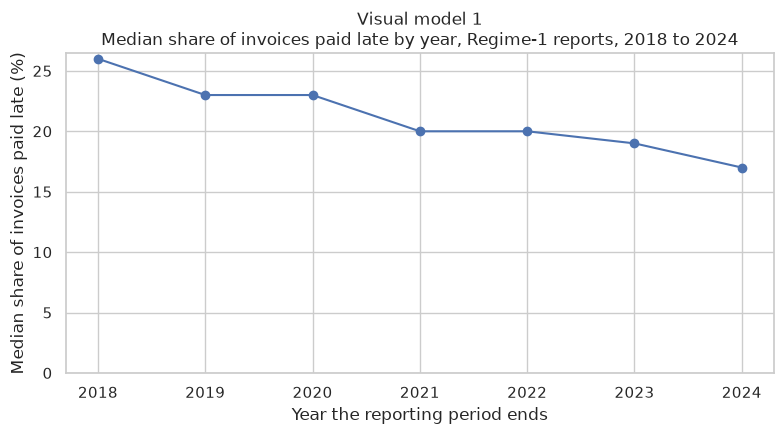

In [42]:
vm1 = plot_yearly_median(
    yearly,
    "Visual model 1",
    "Median share of invoices paid late by year, Regime-1 reports, "
    "2018 to 2024",
)
plt.show()

**What Visual model 1 shows.** The typical Regime-1 report's share of invoices paid late falls from 26% for periods ending in 2018 to 17% in 2024, with no year going back up. It covers every Regime-1 report left after the rulings, between 11,943 and 13,446 a year, so it is the broad picture. But the companies behind each point change from year to year, so on its own I cannot tell from it whether the same companies improved.

In [43]:
period_names = list(PERIODS)
spread = period_summary(paired, period_names)
spread

,2018 to 2019,2023 to 2024
companies,"5,371.00","5,371.00"
mean,29.49,24.29
25%,12.00,7.75
median,25.00,18.50
75%,43.00,35.00


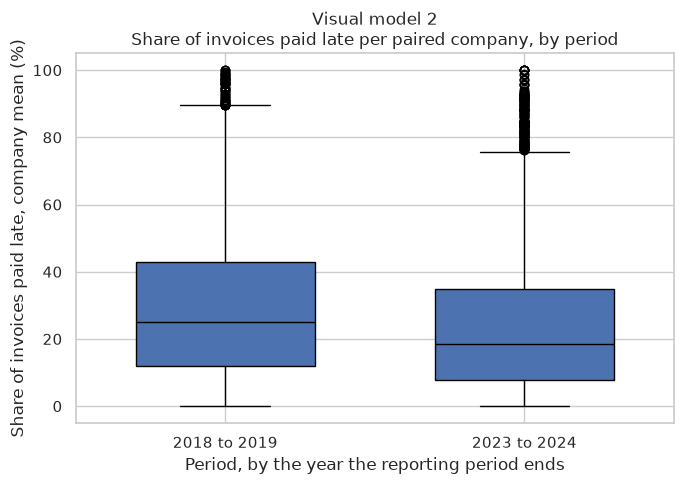

In [44]:
vm2 = plot_periods(
    paired,
    period_names,
    "Visual model 2",
    "Share of invoices paid late per paired company, by period",
)
plt.show()

**What Visual model 2 shows.** For the 5,371 paired companies, the whole box moves down between the periods. The median company mean falls from 25% to 18.50%, the quartiles from 12% and 43% to 7.75% and 35%, and the mean from 29.49% to 24.29%. Both periods run the full range from 0% to 100%, and in 2023 to 2024 more companies sit above the upper whisker, so a minority still pays most invoices late. What I cannot see here is the pairing: a company's place in one box is not linked to its place in the other.

In [45]:
direction = direction_counts(paired, period_names)
direction

below the line: improved    3368
on the line: no change       169
above the line: worsened    1834
Name: companies, dtype: int64

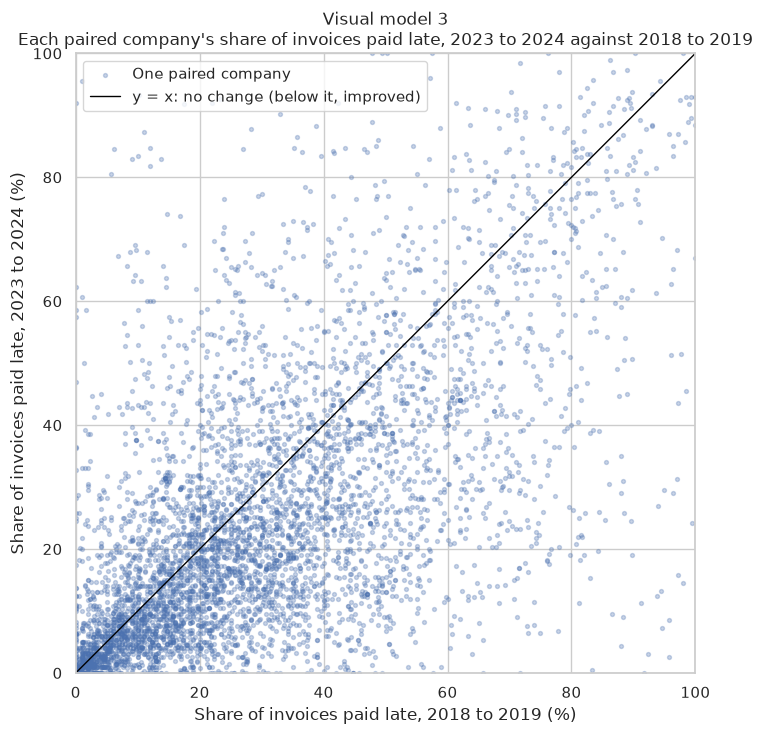

In [46]:
vm3 = plot_paired_scatter(
    paired,
    period_names,
    "Visual model 3",
    "Each paired company's share of invoices paid late, 2023 to 2024 "
    "against 2018 to 2019",
)
plt.show()

**What Visual model 3 shows.** Each point is one paired company, and the line y = x marks no change. 3,368 of the 5,371 companies sit below the line, so their share of invoices paid late fell, 1,834 sit above it and 169 sit on it. Most points crowd the lower left, where companies paid few invoices late in both periods, and the points far from the line show that some companies changed a great deal in either direction. It is the only chart where I can see each company's two figures together, which is how the hypothesis test reads the data. It does the job initial data analysis gives a profile plot, showing "changes and variability of the outcome variable within subjects" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 7, accessed 26 Sep 2026), for two periods: each company's change is how far its point sits above or below the line.

### The fitted model

**The fitted model** is a straight line fitted by least squares with `scipy.stats.linregress`: the share of invoices paid late, in percentage points, as a line in the average time to pay, in days, with one point per Regime-1 report. It is a statistical model, not machine learning: two numbers, a slope and an intercept, found in one step. I chose it because the average time to pay is the plainest other measure of how a company pays, so the line shows how closely the two move together, and whether a relationship found in the earlier years still holds later.

I train it on the reports whose period ends in 2018 to 2022 and evaluate it on those ending in 2023 to 2024, which it never sees. It uses the reports left after the excluding rulings, less the 49 above 365 days, because one average of 4,323,394 days would bend the line on its own.

In [47]:
def model_data(frame, columns, years, regime="Regime-1"):
    """Return the regime's reports in the years that the fitted model can use.

    A report is used when its period ends in the years and it gives both
    the average time to pay and the share of invoices paid late. frame is
    not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for end, regime, days and outcome.
    years : (int, int)
        The first and last year a period may end in.
    regime : str, default "Regime-1"
        The only regime whose reports are used.

    Returns
    -------
    pandas.DataFrame
        The kept rows of frame.
    """
    c = columns
    end_year = frame[c["end"]].dt.year
    first, last = years
    keep = (
        frame[c["regime"]].eq(regime)
        & end_year.between(first, last)
        & frame[c["days"]].notna()
        & frame[c["outcome"]].notna()
    )
    return frame[keep]

In [48]:
# The fitted model also leaves out the reports above 365 days, because the
# average time to pay is its input.
MODEL_EXCLUDED = EXCLUDED + ["Average time to pay above 365 days"]
for_model = flagged[~has_reason(flagged, MODEL_EXCLUDED)]
train = model_data(for_model, col, (2018, 2022))
held_out = model_data(for_model, col, (2023, 2024))
left_out = len(flagged) - len(for_model)
print(f"Reports left out of the fitted model: {left_out:,}")
print(f"Training reports, periods ending 2018 to 2022: {len(train):,}")
print(f"Held-out reports, periods ending 2023 to 2024: {len(held_out):,}")

Reports left out of the fitted model: 10,320
Training reports, periods ending 2018 to 2022: 62,186
Held-out reports, periods ending 2023 to 2024: 24,097


**The model's data.** I leave 10,320 reports out of the fitted model: the 10,271 excluded rows and the 49 above 365 days. That leaves 62,186 Regime-1 reports ending in 2018 to 2022 for training and 24,097 ending in 2023 to 2024 held out. Unlike the hypothesis test, the model works at report level, so a company that reports more often counts more here.

## Training

### Fitting the model on reports ending 2018 to 2022

In [49]:
def fit_line(frame, x, y, confidence=0.95):
    """Fit y as a straight line in x by least squares, and describe the fit.

    The slope's confidence interval comes from its standard error and the
    t distribution with n - 2 degrees of freedom. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per point.
    x, y : str
        The input and outcome columns.
    confidence : float, default 0.95
        The confidence level of the slope's interval.

    Returns
    -------
    pandas.Series
        reports, slope, intercept, r squared, slope standard error, and the
        slope interval's low and high ends.
    """
    result = stats.linregress(frame[x], frame[y])
    n = len(frame)
    margin = stats.t.ppf((1 + confidence) / 2, n - 2) * result.stderr
    level = f"{confidence:.0%} CI"
    return pd.Series(
        {
            "reports": n,
            "slope": result.slope,
            "intercept": result.intercept,
            "r squared": result.rvalue**2,
            "slope standard error": result.stderr,
            f"slope {level} low": result.slope - margin,
            f"slope {level} high": result.slope + margin,
        }
    )

In [50]:
fit = fit_line(train, col["days"], col["outcome"])
print(f"Training reports: {fit['reports']:,.0f}")
per_company = train.groupby(col["company"]).size()
several = (per_company > 1).sum()
print(
    f"Companies behind them: {len(per_company):,}, of which {several:,} "
    f"({100 * several / len(per_company):.2f}%) file more than one"
)
print(f"Slope: {fit['slope']:.4f} percentage points per day")
print(f"Intercept: {fit['intercept']:.2f}%")
print(f"r squared: {fit['r squared']:.4f}")
print(f"Slope standard error: {fit['slope standard error']:.4f}")
print(
    f"Slope 95% confidence interval: {fit['slope 95% CI low']:.4f} to "
    f"{fit['slope 95% CI high']:.4f}"
)

Training reports: 62,186
Companies behind them: 8,334, of which 7,894 (94.72%) file more than one
Slope: 0.4575 percentage points per day
Intercept: 11.53%
r squared: 0.1302
Slope standard error: 0.0047
Slope 95% confidence interval: 0.4482 to 0.4668


**What the training shows.** On the 62,186 training reports, the share of invoices paid late rises by 0.4575 percentage points for each extra day of average time to pay, and the slope's 95% confidence interval, 0.4482 to 0.4668, is narrow and well above zero. So slower payers do report a larger share of invoices paid late. But r squared is 0.1302: the line accounts for only about 13% of the variation between reports. I expected a weak fit, because the share of invoices paid late is measured against each company's own terms, and two companies with the same average can be on very different terms. Most companies file several reports in these years, 7,894 of the 8,334 (94.72%), so the reports are not independent, and the slope's interval above is too narrow, as the company-level bootstrap below shows. Initial data analysis warns that ignoring serial correlation "could lead to biased estimation" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 27, accessed 26 Sep 2026).

In [51]:
def bootstrap_slope(frame, x, y, group, seed, resamples=2000, confidence=0.95):
    """Return a percentile interval for the slope, resampling whole groups.

    Each resample draws as many groups as frame has, with replacement, and
    keeps every row of each group drawn, as often as it is drawn. The
    groups are taken in sorted order and drawn with
    numpy.random.default_rng(seed).integers, so a seed always gives the
    same interval. I fit each resample from the sums of x, y, x squared and
    x times y in each group, which gives the same least-squares slope as
    stacking the drawn rows, without building them. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per point.
    x, y : str
        The input and outcome columns.
    group : str
        The column that says which group, here which company, a row
        belongs to.
    seed : int
        The seed for the random draws.
    resamples : int, default 2000
        How many resamples to draw.
    confidence : float, default 0.95
        The confidence level of the interval.

    Returns
    -------
    pandas.Series
        companies, resamples, the slope's standard error across the
        resamples, and the interval's low and high ends.
    """
    codes, groups = pd.factorize(frame[group], sort=True)
    k = len(groups)
    xs = frame[x].to_numpy(dtype=float)
    ys = frame[y].to_numpy(dtype=float)
    sums = np.column_stack(
        [
            np.bincount(codes, weights=w, minlength=k)
            for w in (np.ones_like(xs), xs, ys, xs * xs, xs * ys)
        ]
    )
    rng = np.random.default_rng(seed)
    slopes = np.empty(resamples)
    for i in range(resamples):
        drawn = np.bincount(rng.integers(0, k, size=k), minlength=k)
        n, sx, sy, sxx, sxy = drawn @ sums
        slopes[i] = (n * sxy - sx * sy) / (n * sxx - sx**2)
    tail = 100 * (1 - confidence) / 2
    low, high = np.percentile(slopes, [tail, 100 - tail])
    level = f"{confidence:.0%} CI"
    return pd.Series(
        {
            "companies": k,
            "resamples": resamples,
            "slope standard error": slopes.std(ddof=1),
            f"slope {level} low": low,
            f"slope {level} high": high,
        }
    )

In [52]:
# Any fixed seed will do; I fix one so the interval is the same on every run.
SEED = 2026
boot = bootstrap_slope(
    train, col["days"], col["outcome"], col["company"], SEED
)
analytic_width = fit["slope 95% CI high"] - fit["slope 95% CI low"]
boot_width = boot["slope 95% CI high"] - boot["slope 95% CI low"]
print(
    f"Companies resampled: {boot['companies']:,.0f}, "
    f"{boot['resamples']:,.0f} times, seed {SEED}"
)
print(
    "Analytic 95% CI, each report independent: "
    f"{fit['slope 95% CI low']:.4f} to {fit['slope 95% CI high']:.4f} "
    f"(standard error {fit['slope standard error']:.4f})"
)
print(
    "Bootstrap 95% CI, companies resampled: "
    f"{boot['slope 95% CI low']:.4f} to {boot['slope 95% CI high']:.4f} "
    f"(standard error {boot['slope standard error']:.4f})"
)
ratio = boot_width / analytic_width
print(f"The bootstrap interval is {ratio:.1f} times as wide")

Companies resampled: 8,334, 2,000 times, seed 2026
Analytic 95% CI, each report independent: 0.4482 to 0.4668 (standard error 0.0047)
Bootstrap 95% CI, companies resampled: 0.4303 to 0.4865 (standard error 0.0146)
The bootstrap interval is 3.0 times as wide


**The slope's interval with companies resampled.** Resampling the 8,334 training companies whole, 2,000 times, gives a 95% interval for the slope of 0.4303 to 0.4865. That is 3.0 times as wide as the analytic 0.4482 to 0.4668, so the analytic interval was too narrow, as I expected, because a company's reports move together. The slope stays well above zero either way, so I still read the fitted model as showing that slower payment goes with a larger share of invoices paid late.

## Evaluation

### The fitted model on held-out reports

In [53]:
def mean_absolute_error(frame, x, y, fit):
    """Return the mean absolute gap between y and the fitted line's value.

    frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per point.
    x, y : str
        The input and outcome columns.
    fit : pandas.Series
        A fit from fit_line, with its slope and intercept.

    Returns
    -------
    float
        In the outcome's units.
    """
    predicted = fit["intercept"] + fit["slope"] * frame[x]
    return (frame[y] - predicted).abs().mean()


def plot_fitted_model(frame, x, y, fit, caption, title, x_label, y_label):
    """Draw the points and the fitted line across their range of x.

    The y axis keeps to the points' own range, so where the line runs past
    every point it leaves the top of the chart.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per point.
    x, y : str
        The input and outcome columns.
    fit : pandas.Series
        A fit from fit_line, with its slope and intercept.
    caption : str
        The first line of the chart's title, such as "Fitted model".
    title : str
        The descriptive title, on the second line.
    x_label, y_label : str
        The axis labels, with their units.

    Returns
    -------
    matplotlib.axes.Axes
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(frame[x], frame[y], s=6, alpha=0.15, label="One report")
    ends = [frame[x].min(), frame[x].max()]
    ax.plot(
        ends,
        [fit["intercept"] + fit["slope"] * end for end in ends],
        color="black",
        linewidth=1.5,
        label="Fitted line",
    )
    low, high = frame[y].min(), frame[y].max()
    margin = (high - low) * 0.05
    ax.set_ylim(low - margin, high + margin)
    ax.set_title(f"{caption}\n{title}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.legend(loc="lower right")
    fig.tight_layout()
    return ax

In [54]:
errors = pd.DataFrame(
    {
        "reports": [len(train), len(held_out)],
        "mean absolute error (pp)": [
            mean_absolute_error(train, col["days"], col["outcome"], fit),
            mean_absolute_error(held_out, col["days"], col["outcome"], fit),
        ],
    },
    index=["training, ending 2018 to 2022", "held out, ending 2023 to 2024"],
)
print(
    "The fitted line reaches 100% at "
    f"{(100 - fit['intercept']) / fit['slope']:.0f} days"
)
errors

The fitted line reaches 100% at 193 days


,reports,mean absolute error (pp)
"training, ending 2018 to 2022",62186,17.65
"held out, ending 2023 to 2024",24097,17.00


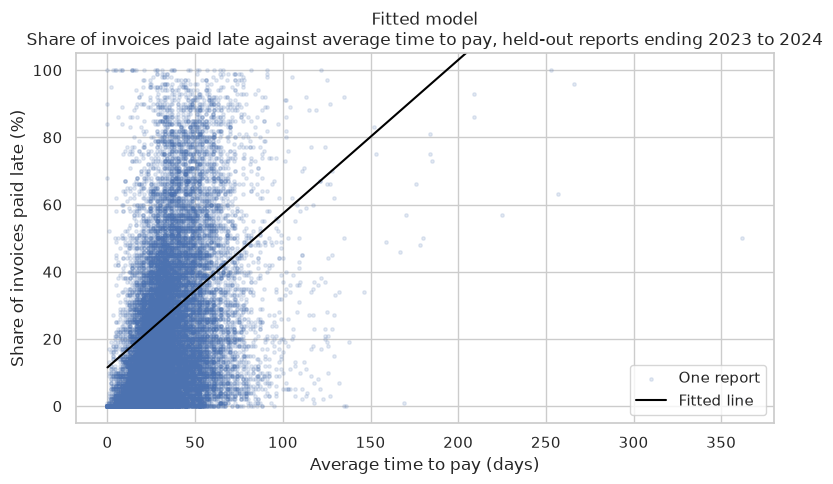

In [55]:
fitted_ax = plot_fitted_model(
    held_out,
    col["days"],
    col["outcome"],
    fit,
    "Fitted model",
    "Share of invoices paid late against average time to pay, held-out "
    "reports ending 2023 to 2024",
    "Average time to pay (days)",
    "Share of invoices paid late (%)",
)
plt.show()

**How the fitted model does on reports it never saw.** The line misses a report's share of invoices paid late by 17.65 percentage points on average in training and by 17.00 on the 24,097 held-out reports. So it does no worse on the later years: with only a slope and an intercept, there is little to overfit. But a typical miss of 17 points is large next to a median share of 17% to 26%, which matches the r squared of 0.1302. The chart shows why: at any average time to pay, reports run from 0% to 100% late, and the line passes 100% at 193 days, which no share can reach. I read the fitted model as evidence that slower payment goes with a larger share of invoices paid late, not as a way to predict a single company's figure.

### Task 4: Comparing the visual models

In [56]:
first, last = period_names
median = "median share of invoices paid late (%)"
improved = direction["below the line: improved"]
comparison = pd.DataFrame(
    {
        "statistic it shows": [
            "Median share of invoices paid late across all Regime-1 reports, "
            "by year",
            "Spread of the paired companies' means in each period: median "
            "and quartiles",
            "Each paired company's change: below the line y = x it improved",
        ],
        "value": [
            f"{yearly.loc[2018, median]:.0f}% in 2018 to "
            f"{yearly.loc[2024, median]:.0f}% in 2024",
            f"median {spread.loc['median', first]:.2f}% in {first}, "
            f"{spread.loc['median', last]:.2f}% in {last}",
            f"{improved:,} of {len(paired):,} companies "
            f"({100 * improved / len(paired):.2f}%) below the line",
        ],
        "what it hides": [
            "Which companies report: the mix changes each year, and no "
            "company's own change shows",
            "The pairing: a company's place in one box is not linked to its "
            "place in the other",
            "The size of the typical change, and where points overlap in "
            "the crowded lower left",
        ],
        "trade-off": [
            "Shows every year of the trend, at the cost of mixing different "
            "companies",
            "Compares the two periods' spread at a glance, but drops the "
            "pairing the test relies on",
            "Shows the pairing directly, but shows direction better than "
            "size",
        ],
    },
    index=["Visual model 1", "Visual model 2", "Visual model 3"],
)
comparison

,statistic it shows,value,what it hides,trade-off
Visual model 1,"Median share of invoices paid late across all Regime-1 reports, by year",26% in 2018 to 17% in 2024,"Which companies report: the mix changes each year, and no company's own change shows","Shows every year of the trend, at the cost of mixing different companies"
Visual model 2,Spread of the paired companies' means in each period: median and quartiles,"median 25.00% in 2018 to 2019, 18.50% in 2023 to 2024",The pairing: a company's place in one box is not linked to its place in the other,"Compares the two periods' spread at a glance, but drops the pairing the test relies on"
Visual model 3,Each paired company's change: below the line y = x it improved,"3,368 of 5,371 companies (62.71%) below the line","The size of the typical change, and where points overlap in the crowded lower left","Shows the pairing directly, but shows direction better than size"


**Which visual model best supports the question.** All three point the same way: the yearly median falls from 26% to 17%, the paired companies' median from 25% to 18.50%, and 3,368 of the 5,371 paired companies (62.71%) sit below the line. They differ in what they let me compare. Visual model 1 mixes companies that come and go, and Visual model 2 shows two separate crowds, so neither can show that the same companies changed. I judge that Visual model 3 best supports the question, because it keeps each company's two figures together, as the question and the paired test do. Its weakness is size: it shows how many companies improved, not by how much, which is why the test below measures the mean change.

### Task 5: Hypothesis test

In [57]:
def within_company_correlation(table, names):
    """Return how closely each company's two figures move together.

    r is Pearson's correlation between the companies' first and last
    period figures, taken with pandas, so no test is run. Beside it are
    the standard deviation in each period and of the changes. table is not
    changed.

    Parameters
    ----------
    table : pandas.DataFrame
        The analysis table.
    names : list of str
        The period columns, earliest first.

    Returns
    -------
    pandas.Series
        paired companies, r between the periods, the standard deviation in
        each period and the standard deviation of the changes.
    """
    first, last = table[names[0]], table[names[-1]]
    return pd.Series(
        {
            "paired companies": len(table),
            "r between the periods": first.corr(last),
            f"standard deviation, {names[0]}": first.std(),
            f"standard deviation, {names[-1]}": last.std(),
            "standard deviation of the changes": (last - first).std(),
        }
    )

In [58]:
within = within_company_correlation(paired, period_names)
print(f"Paired companies: {within['paired companies']:,.0f}")
print(f"r between the periods: {within['r between the periods']:.4f}")
for name in period_names:
    spread_in = within[f"standard deviation, {name}"]
    print(f"Standard deviation, {name}: {spread_in:.2f} pp")
changes_spread = within["standard deviation of the changes"]
print(f"Standard deviation of the changes: {changes_spread:.2f} pp")

Paired companies: 5,371
r between the periods: 0.6368
Standard deviation, 2018 to 2019: 22.36 pp
Standard deviation, 2023 to 2024: 21.29 pp
Standard deviation of the changes: 18.63 pp


Each paired company's two means are strongly related (r = 0.64), as initial data analysis expects: "The repeated measurements from the same subject in longitudinal studies are usually correlated" ([Lusa et al., 2024](https://doi.org/10.1371/journal.pone.0295726), p. 9, accessed 26 Sep 2026). So I test each company's own change, whose standard deviation of 18.63 points is smaller than the spread in either period (22.36 and 21.29), instead of comparing the two periods as separate groups.

The question compares the same companies in two periods, so each company gives a pair of figures and the test works on each company's change, its 2023 to 2024 mean minus its 2018 to 2019 mean, in percentage points. I use a paired t-test, `scipy.stats.ttest_rel`, on the paired companies in the analysis table.

- **H0:** the mean change in the share of invoices paid late for the paired companies is zero.
- **H1:** the mean change is not zero (two-sided).

I fix the significance level in the next cell, before the test runs.

In [59]:
ALPHA = 0.05
print(f"Significance level, fixed before the test: alpha = {ALPHA}")

Significance level, fixed before the test: alpha = 0.05


In [60]:
def paired_t_test(table, names, confidence=0.95):
    """Run the paired t-test on the change between two periods.

    The change is the last period minus the first, per company. Cohen's
    d_z is the mean change divided by the standard deviation of the
    changes. table is not changed.

    Parameters
    ----------
    table : pandas.DataFrame
        The analysis table.
    names : list of str
        The period columns, earliest first.
    confidence : float, default 0.95
        The confidence level of the interval for the mean change.

    Returns
    -------
    pandas.Series
        paired companies, mean change (pp), the interval's low and high
        ends, t, degrees of freedom, p-value (two-sided) and d_z.
    """
    before, after = table[names[0]], table[names[-1]]
    change = after - before
    result = stats.ttest_rel(after, before)
    summary = mean_with_ci(change, confidence)
    level = f"{confidence:.0%} CI"
    return pd.Series(
        {
            "paired companies": int(summary["n"]),
            "mean change (pp)": summary["mean"],
            f"{level} low": summary[f"{level} low"],
            f"{level} high": summary[f"{level} high"],
            "t": result.statistic,
            "degrees of freedom": result.df,
            "p-value": result.pvalue,
            "d_z": change.mean() / change.std(),
        }
    )


def plot_assumption_check(values, caption, title):
    """Draw a histogram and a normal Q-Q plot of values, side by side.

    Parameters
    ----------
    values : pandas.Series
        The paired changes, in percentage points.
    caption : str
        The first line of the figure's title, such as "Assumption check".
    title : str
        The descriptive title, on the second line.

    Returns
    -------
    matplotlib.figure.Figure
    """
    fig, (hist, qq) = plt.subplots(1, 2, figsize=(11, 4.5))
    hist.hist(values, bins=60, color=sns.color_palette()[0])
    hist.set_xlabel("Change in share of invoices paid late (pp)")
    hist.set_ylabel("Paired companies")
    hist.set_title("Histogram of the changes")
    stats.probplot(values, dist="norm", plot=qq)
    qq.set_title("Q-Q plot against a normal distribution")
    qq.set_xlabel("Normal quantiles")
    qq.set_ylabel("Ordered changes (pp)")
    fig.suptitle(f"{caption}\n{title}")
    fig.tight_layout()
    return fig

Paired companies: 5,371
Skewness of the changes: -0.07


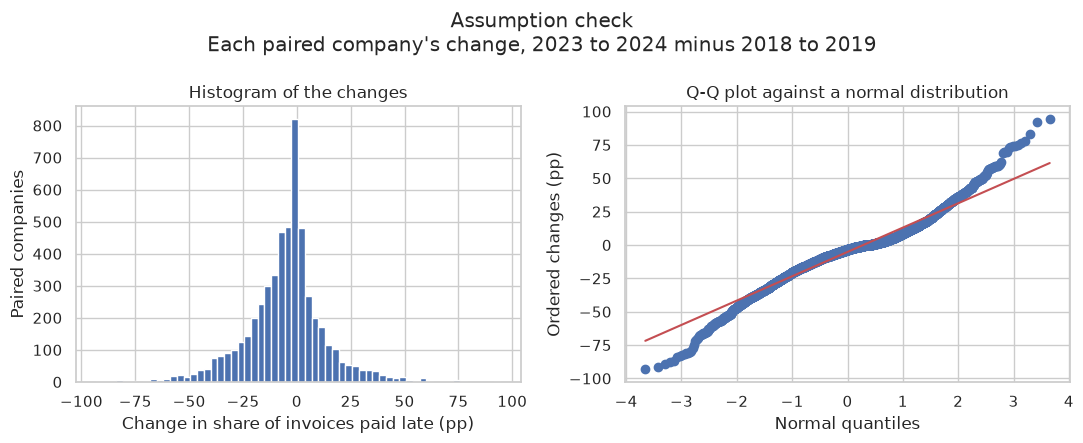

In [61]:
changes = paired["change"]
print(f"Paired companies: {changes.count():,}")
print(f"Skewness of the changes: {changes.skew():.2f}")
assumption_fig = plot_assumption_check(
    changes,
    "Assumption check",
    "Each paired company's change, 2023 to 2024 minus 2018 to 2019",
)
plt.show()

**The assumption check.** The paired t-test assumes the changes come from a roughly normal distribution, or that there are enough pairs for their mean to be close to normal. I check this descriptively, with one number (the skewness) and one figure (a histogram and a Q-Q plot), not with a second formal test. The changes are close to symmetric, with a skewness of -0.07, and peak sharply near zero. The Q-Q plot follows the line in the middle but bends away at both ends, so the tails are heavier than a normal distribution's. With 5,371 paired companies and so little skew, the mean of the changes is close to normal even so. The share of invoices paid late is itself skewed, with a skew of 1.06 in Task 3. That does not rule out the t-test on a sample this large: "For studies with a large sample size, t-tests and their corresponding confidence intervals can and should be used even for heavily skewed data" ([Fagerland, 2012](https://doi.org/10.1186/1471-2288-12-78), p. 1, accessed 6 Oct 2026). So I judge the paired t-test sound here. I test at alpha = 0.05, two-sided, as fixed above.

In [62]:
result = paired_t_test(paired, period_names)
p_value = result["p-value"]
print(f"Paired companies: {result['paired companies']:,.0f}")
print(
    "Mean change, 2023 to 2024 minus 2018 to 2019: "
    f"{result['mean change (pp)']:.2f} pp"
)
print(
    f"95% confidence interval: {result['95% CI low']:.2f} to "
    f"{result['95% CI high']:.2f} pp"
)
print(
    f"t = {result['t']:.2f}, "
    f"degrees of freedom = {result['degrees of freedom']:.0f}"
)
print(f"p-value = {p_value:.2e} (two-sided), below 0.001: {p_value < 0.001}")
print(f"Cohen's d_z = {result['d_z']:.3f}")
decision = "reject H0" if p_value < ALPHA else "do not reject H0"
print(f"p-value below alpha = {ALPHA}: {p_value < ALPHA}, so I {decision}")

Paired companies: 5,371
Mean change, 2023 to 2024 minus 2018 to 2019: -5.20 pp
95% confidence interval: -5.70 to -4.70 pp
t = -20.45, degrees of freedom = 5370
p-value = 1.39e-89 (two-sided), below 0.001: True
Cohen's d_z = -0.279
p-value below alpha = 0.05: True, so I reject H0


**The result.** For the 5,371 paired companies, the share of invoices paid late fell by 5.20 percentage points on average from 2018 to 2019 to 2023 to 2024, with a 95% confidence interval of -5.70 to -4.70. The test gives t = -20.45 on 5,370 degrees of freedom and p < 0.001, below alpha = 0.05, so I reject H0: the same companies paid a smaller share of their invoices late in the later period. Cohen's d_z is -0.279, so the fall is clear but modest next to how much companies differ in their change. I give the full reading in the report.

### The effect of the screening on the test

In [63]:
# Each row rebuilds the analysis table without one set of reports and gives
# the paired mean change, so I can see whether the result rests on them.
impossible_rows = has_reason(flagged, ["Figures that cannot all be true"])
runs = {
    "The hypothesis test: every ruling applied": excluded,
    "Every report": pd.Series(False, index=flagged.index),
    "Every report, without the code-breach reports": breach,
    "Every report, without the impossible-figures reports": impossible_rows,
}
rows = {}
for label, dropped in runs.items():
    table, _ = build_analysis_table(flagged[~dropped], col, PERIODS)
    rows[label] = mean_with_ci(table["change"])
effect = pd.DataFrame(rows).T.rename(
    columns={"n": "paired companies", "mean": "mean change (pp)"}
)
effect["paired companies"] = effect["paired companies"].astype(int)
effect

,paired companies,mean change (pp),95% CI low,95% CI high
The hypothesis test: every ruling applied,5371,-5.20,-5.70,-4.70
Every report,5376,-5.17,-5.67,-4.67
"Every report, without the code-breach reports",5236,-4.90,-5.40,-4.39
"Every report, without the impossible-figures reports",5371,-5.19,-5.69,-4.69


**The result does not rest on the screened reports.** With every report, 5,376 companies are paired and the mean change is -5.17 percentage points. Taking out the 2,587 code-breach reports leaves 5,236 companies and a change of -4.90, and taking out the 370 impossible-figures reports gives -5.19. The hypothesis test, with every ruling applied, gives -5.20. All four 95% confidence intervals lie between -5.70 and -4.39, so every run shows the same clear fall, and I do not change the test's conclusion.

### Two findings made after looking at the data

I found these two comparisons after looking at the data. They are not part of the planned analysis, which answers the question with the one hypothesis test above. The first relates when a company published its reports to the change in its share of invoices paid late, and the second relates whether a report names a payment code to the share itself. So each is an association, not a cause, and I give each without a test.

In [64]:
def mean_change_by_group(table, groups, confidence=0.95):
    """Return each group's companies, mean change and confidence interval.

    table is not changed.

    Parameters
    ----------
    table : pandas.DataFrame
        The analysis table, with its change column.
    groups : pandas.Series
        The group label for each company, on table's index.
    confidence : float, default 0.95
        The confidence level of each interval.

    Returns
    -------
    pandas.DataFrame
        One row per group, in label order: companies, mean change (pp) and
        the interval's low and high ends.
    """
    rows = {
        label: mean_with_ci(changes, confidence)
        for label, changes in table["change"].groupby(groups)
    }
    out = pd.DataFrame(rows).T.rename(
        columns={"n": "companies", "mean": "mean change (pp)"}
    )
    out["companies"] = out["companies"].astype(int)
    return out

In [65]:
# The reports behind each paired company's 2023 to 2024 figure, and whether
# any of them was published late.
rows = analysis_rows(flagged[~excluded], col, PERIODS)
behind_later = rows[
    rows["period"].eq("2023 to 2024") & rows[col["company"]].isin(paired.index)
]
filed_late = (
    late[behind_later.index].groupby(behind_later[col["company"]]).any()
)
filer = filed_late.reindex(paired.index).map(
    {
        True: "Published a 2023 to 2024 report late",
        False: "Published every 2023 to 2024 report on time",
    }
)
by_filing = mean_change_by_group(paired, filer)
by_filing

,companies,mean change (pp),95% CI low,95% CI high
Published a 2023 to 2024 report late,2985,-4.00,-4.70,-3.30
Published every 2023 to 2024 report on time,2386,-6.70,-7.40,-6.00


**Late publishers improved less.** Of the 5,371 paired companies, 2,985 published at least one of the 2023 to 2024 reports behind their figure late. Their share of invoices paid late fell by 4.00 percentage points on average (95% confidence interval -4.70 to -3.30), against 6.70 points (-7.40 to -6.00) for the 2,386 companies that published every one on time. The two intervals do not overlap. I read it only as an association: the companies that missed the publishing deadline tended to improve less on paying invoices within agreed terms.

In [66]:
def median_share_by_group(frame, columns, groups):
    """Return each group's reports and median share of invoices paid late.

    frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per report.
    columns : dict of str to str
        Role to column name, for outcome.
    groups : dict of str to pandas.Series of bool
        Group label to its reports, on frame's index.

    Returns
    -------
    pandas.DataFrame
        One row per group: reports and the median share of invoices paid
        late (%).
    """
    outcome = frame[columns["outcome"]]
    rows = {}
    for label, members in groups.items():
        median = outcome[members].median()
        rows[label] = {
            "reports": int(members.sum()),
            "median share of invoices paid late (%)": median,
        }
    return pd.DataFrame.from_dict(rows, orient="index")

In [67]:
code_medians = median_share_by_group(
    flagged,
    col,
    {
        "Signatory reports": tested,
        "Reports that name no code": names_no_code,
    },
)
code_medians

,reports,median share of invoices paid late (%)
Signatory reports,8159,12.00
Reports that name no code,95971,21.00


**Signatory reports and the rest.** The median signatory report gives 12% of invoices paid late, against 21% for the 95,971 reports that name no code. So signatory reports show a smaller share of invoices paid late on this measure, but I read it only as an association: a company that chooses to sign a code may differ from the rest in ways the data does not show.

## Summary

### Task 6: Notebook summary

I explored 115,358 payment practice reports that large UK companies published from 2017 up to my export on 6 October 2026, and asked whether the same companies paid a smaller share of invoices late in 2023 to 2024 than in 2018 to 2019. They did: for 5,371 paired companies the share fell by 5.20 percentage points on average (95% confidence interval for the change, -5.70 to -4.70), a clear but modest change.

What I did not expect: of the signatory reports I could test, those naming the Prompt Payment Code or Fair Payment Code as the company's own, 31.71% are in breach of the code standard (95% of invoices paid within 60 days) on their own figures. Separately, 28.63% of all reports were published late, after the 30-day legal deadline, with no improvement over the years.

The main challenge was the data: what look like typing errors, such as an average time to pay of 4,323,394 days, repeat filings for one period and figures that cannot all be true, and I ruled on each before the analysis used it. The fitted model shows that slower payers report a larger share of invoices paid late, but it explains only about 13% of the variation, so I read it as a relationship, not a forecast.